# Run the antimalarial GNN pipeline

This notebook is a front end for the tool in this same folder — it
doesn't reimplement anything, it just imports `config`, `data_prep`,
`models`, `train`, `baseline`, `stats_analysis`, and `explain` from the
`.py` files sitting right next to this notebook, and calls them.

Settings live in `config.toml`. Edit the values in the cell below (it's
just the contents of that file as a string), run it, and everything
after reads from the updated config — no digging through the other
files to change a setting.

If you'd rather use the command line instead of this notebook, `run.py`
does the same thing with `python run.py cv` / `stats` / `explain` / `all`.


## Settings

Edit anything below, then run this cell.

In [ ]:
settings = """
[data]
path = "main_data_2/Drug_activity.csv"
cache_path = "enhanced_drug_data_with_descriptors.csv"
use_cache = true  # skips recomputing descriptors if this file already exists
graph_cache_path = "molecule_graphs.pt"  # cached graphs, keyed by SMILES

# balances the whole dataset before anything else happens, so train/val/test
# all come from the same balanced pool instead of the real imbalanced one.
# means test accuracy/precision reflect a 50/50 world, not reality -- worth
# saying that explicitly if you end up reporting these numbers. flip to
# false to go back to balancing training folds only and leaving val/test
# at the real distribution.
balance_full_dataset = true
balanced_path = "main_data_2/Drug_activity_balanced.csv"
balanced_cache_path = "balanced_descriptors.csv"
balanced_graph_cache_path = "balanced_molecule_graphs.pt"

[run]
seed = 42
device = "cpu"  # cuda if you have it, mps is flaky here so just skip it

[crossval]
folds = 5
correlation_threshold = 0.85
models = []          # empty = run all four, or list e.g. ["gcn", "gat"]
skip_baseline = false
baseline_models = [] # empty = run all five

[training]
epochs = 200
initial_lr = 0.001
weight_decay = 1e-4
early_stop_patience = 25
batch_size = 64 
hidden_dim = 128
dropout = 0.2

[explain]
n_molecules = 20

[tuning]
test_size = 0.2  # held-out 20% test set
folds = 10        
epochs = 25     
patience = 6

[eda]
enabled_by_default = true

[visualize]
n_molecules = 3

[paths]
output_dir = "test_results"
model_dir = "trained_models"
history_dir = "training_history"
figure_dir = "figures"
"""

with open('config.toml', 'w') as f:
    f.write(settings)

import config
config.reload_config()

print(f"data path:        {config.RAW_DATA_PATH}")
print(f"balance full ds:  {config.BALANCE_FULL_DATASET}")
print(f"seed:             {config.SEED}")
print(f"cv folds:         {config.N_FOLDS}")
print(f"models to run:    {config.CV_MODELS or 'all four'}")
print(f"baselines to run: {config.BASELINE_MODELS or 'all five'}")
print(f"skip baseline:    {config.SKIP_BASELINE}")
print(f"training config:  {config.TRAIN_CONFIG}")
print(f"tuning: {config.TUNE_FOLDS}-fold CV inside {int((1-config.TUNE_TEST_SIZE)*100)}% train, up to {config.TUNE_EPOCHS} epochs, patience {config.TUNE_PATIENCE}")
print(f"device:           {config.DEVICE}")

config reloaded from config.toml
data path:        main_data_2/Drug_activity.csv
balance full ds:  True
seed:             42
cv folds:         5
models to run:    all four
baselines to run: all five
skip baseline:    False
training config:  {'epochs': 200, 'initial_lr': 0.001, 'weight_decay': 0.0001, 'early_stop_patience': 25, 'batch_size': 64, 'hidden_dim': 128, 'dropout': 0.2}
tuning: 3-fold CV inside 80% train, up to 25 epochs, patience 6
device:           cpu


## Save a class-balanced copy of the whole dataset

**ON by default** (controlled by `[data] balance_full_dataset` in the
settings cell above). The ENTIRE dataset gets balanced once (random
undersampling of the majority class) and saved to a new file — then
everything downstream (`cv`, `train-final`, baselines) trains **and
tests** on that balanced distribution, not the real class balance.

**This is a real, deliberate tradeoff, not a bug**: reported test
accuracy/precision describe performance in an artificial 50/50 world,
not the real-world class distribution. State that explicitly in your
methods section — a reviewer comparing your reported class balance
against your EDA section's real one will otherwise wonder why they
don't match.

Set `balance_full_dataset = false` in the settings cell above to go
back to the other default instead (balance training folds only, leave
validation/test at the real distribution). If you just want confusion
matrices that are easier to read without either tradeoff,
`compare.plot_balanced_confusion_matrix()` further down gives you a
supplementary balanced view built from the same test set, with no
downside either way.

In [ ]:
USE_BALANCED_DATASET = config.BALANCE_FULL_DATASET  # driven by config.toml's [data] balance_full_dataset (default: True)

if USE_BALANCED_DATASET:
    from data_prep import save_balanced_dataset
    balanced_path = config.BALANCED_PATH
    save_balanced_dataset(config.RAW_DATA_PATH, balanced_path, seed=config.SEED)

    # point the pipeline at the balanced file, and use separate cache
    # filenames so this doesn't collide with any cache already built
    # from the real, imbalanced source data
    config.RAW_DATA_PATH = balanced_path
    config.CACHE_PATH = config.BALANCED_CACHE_PATH
    config.GRAPH_CACHE_PATH = config.BALANCED_GRAPH_CACHE_PATH
    print(f"pipeline now points at {balanced_path} -- everything below trains AND tests on balanced data")
else:
    print("balance_full_dataset = false in the settings cell above to get here")


123745 compounds after cleaning (12685 active, 111060 inactive)
balanced dataset: 25370 compounds (12685 active, 12685 inactive) — dropped 98375 excess majority-class compounds
saved to main_data_2/Drug_activity_balanced.csv
pipeline now points at main_data_2/Drug_activity_balanced.csv -- everything below trains AND tests on balanced data


## Load and clean the data

Drops rows with missing labels, SMILES RDKit can't parse, and duplicates.
Descriptors get computed once and cached to `enhanced_drug_data_with_descriptors.csv` (matches the filename the original workflow used) — subsequent runs load from there instead of recomputing all 104 descriptors, which matters once your dataset is in the tens or hundreds of thousands of compounds.

In [3]:
import data_prep

config.set_seed()

# descriptors get cached to config.CACHE_PATH after the first run
# (104 descriptors across a large dataset is slow to redo every time) —
# set force_recompute=True below if your source CSV changed
dataset_df = data_prep.build_full_dataset(
    config.RAW_DATA_PATH,
    cache_path=config.CACHE_PATH,
    use_cache=config.USE_CACHE,
    force_recompute=False,
)
dataset_df.sample(min(5, len(dataset_df)))


loading cached descriptors from balanced_descriptors.csv (pass force_recompute=True, or delete this file, to rebuild from main_data_2/Drug_activity_balanced.csv)
25370 compounds loaded (12685 active, 12685 inactive)


,Smiles,Labels,MolWt,LogP,NumHDonors,NumHAcceptors,TPSA,NumRotatableBonds,NumAromaticRings,NumAliphaticRings,...,fr_pyridine,fr_thiazole,fr_thiophene,NumBridgeheadAtoms,NumSpiroAtoms,NumAmideBonds,NumHBA,NumHBD,NumLipinskiHBA,NumLipinskiHBD
6460,C[C@H]1CN(C(=O)C2=C(N=CC(=C2)C3=CC(=CC=C3)OC)O...,0,564.664,3.16968,1,8,133.06,8,3,1,...,1,0,0,0,0,1,8,1,10,1
11061,N=C(N)c1ccc(O)c(-c2cc3cc(C(=N)N)ccc3o2)c1,1,294.314,2.37354,5,4,133.11,3,3,0,...,0,0,0,0,0,0,4,5,6,7
16563,CC(=O)O[C@H](C)[C@H]1/C=C/C=C\C(=O)O[C@@H]2C[C...,1,556.652,3.91350,0,9,109.89,2,0,5,...,0,0,0,2,2,0,9,0,9,0
22991,COC1=CC=C(C=C1)C2=CC3=C(C=C2)N[C@H]([C@H]4[C@@...,0,480.586,3.90910,2,6,88.10,6,3,2,...,0,0,0,0,0,0,6,2,7,2
6798,CN1CCN(CC1)C(=O)C[C@H]2C[C@H]3[C@@H]([C@H](O2)...,0,443.544,1.58370,2,6,91.34,6,1,4,...,0,0,0,0,0,2,6,2,8,2


## Exploratory data analysis

Dataset overview, descriptor distributions split by activity, Lipinski
rule-of-five compliance, and correlation heatmaps. Nothing here feeds
into the model — it's for getting a feel for the dataset before you
trust anything downstream.

total compounds: 25370
descriptors: 104
active: 12685 (50.0%)
inactive: 12685 (50.0%)
class balance ratio (active/inactive): 1.000


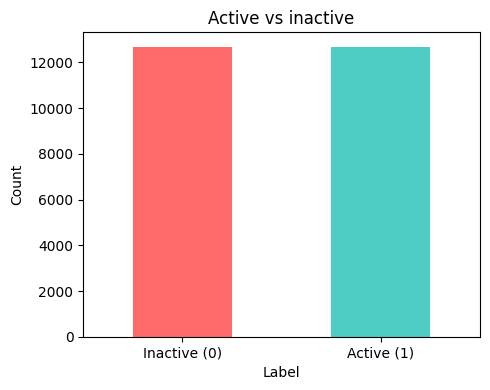

In [4]:
import eda

descriptor_cols = [c for c in dataset_df.columns if c not in ('Smiles', 'Labels')]

eda.dataset_overview(dataset_df)
eda.plot_label_distribution(dataset_df)

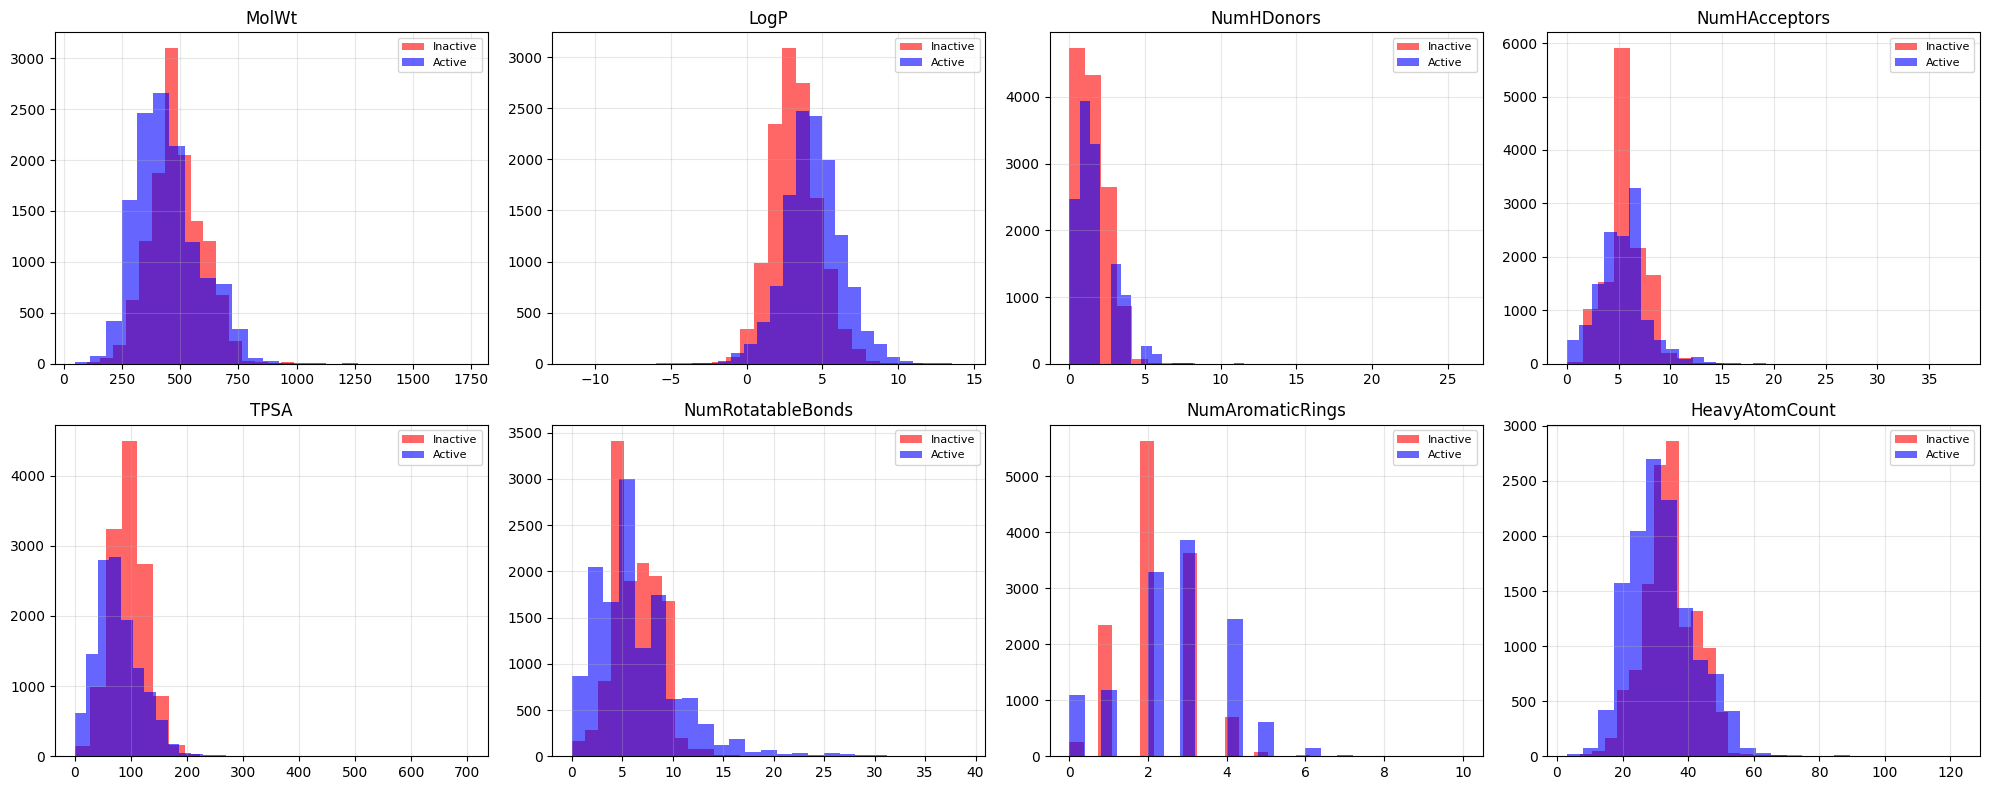

In [5]:
eda.plot_descriptor_distributions(dataset_df)

In [6]:
eda.lipinski_analysis(dataset_df)
comparison = eda.activity_comparison_table(dataset_df)
comparison

Lipinski compliant (<=1 violation): 21090 (83.1%)
non-compliant: 4280 (16.9%)


,descriptor,active_mean,inactive_mean,difference
0,MolWt,448.165573,485.865218,-37.699645
1,LogP,4.425628,3.188847,1.236781
2,NumHDonors,1.720536,1.960110,-0.239574
3,NumHAcceptors,5.256523,5.876941,-0.620418
4,TPSA,78.909436,97.427194,-18.517757
5,NumRotatableBonds,6.396295,6.356090,0.040205
6,NumAromaticRings,2.637209,2.199764,0.437446
7,HeavyAtomCount,31.906583,34.435317,-2.528735


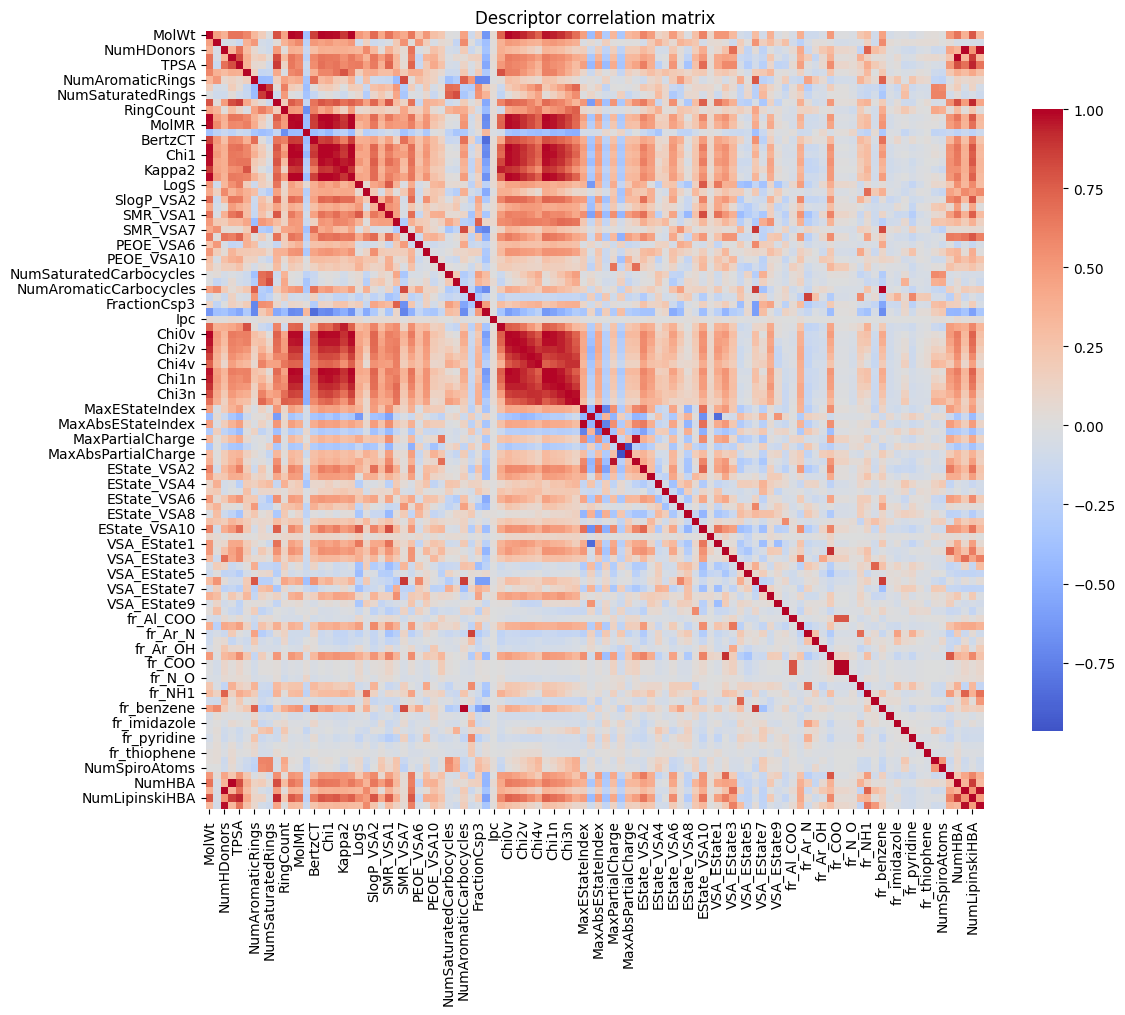

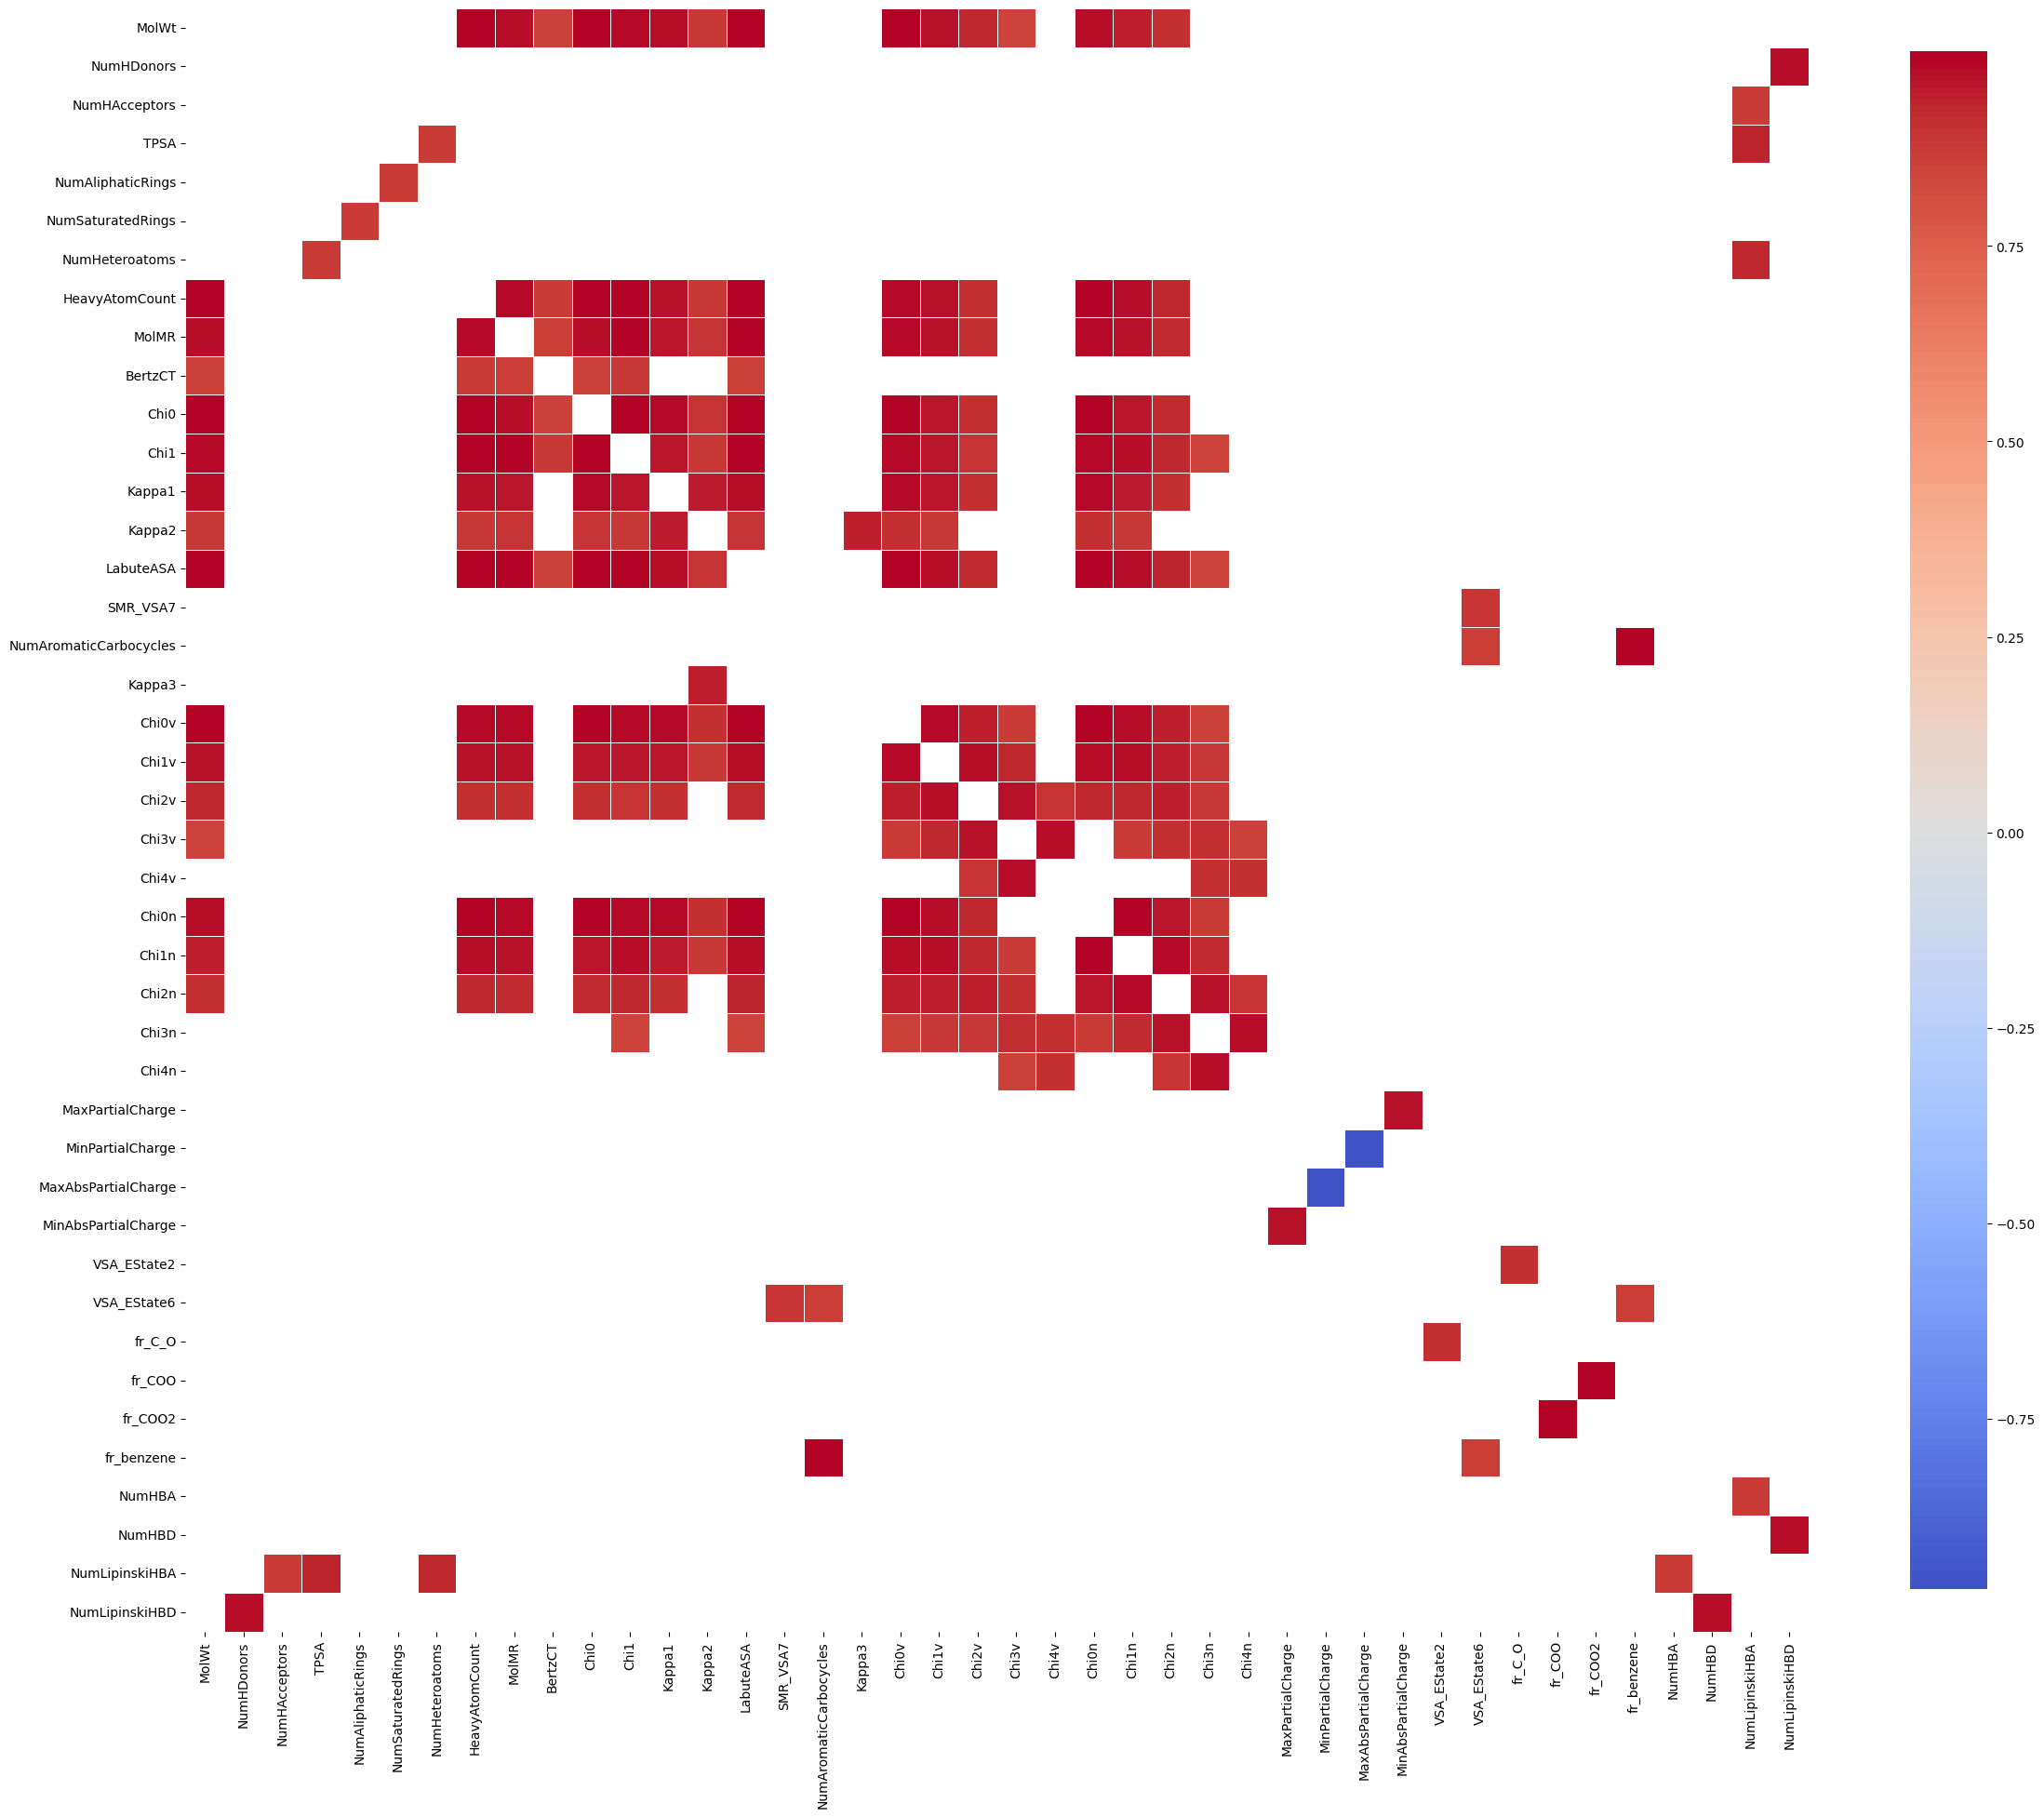

top 10 descriptors correlated with activity:
  EState_VSA2              : 0.5113
  SlogP_VSA2               : 0.4402
  NumAmideBonds            : 0.3971
  fr_Al_OH                 : 0.3586
  MaxEStateIndex           : 0.3522
  MaxAbsEStateIndex        : 0.3522
  EState_VSA10             : 0.3424
  LogP                     : 0.3322
  MinAbsEStateIndex        : 0.3306
  NumLipinskiHBA           : 0.2941


In [7]:
eda.correlation_heatmap(dataset_df, descriptor_cols)
eda.high_correlation_heatmap(dataset_df, descriptor_cols)
_ = eda.top_correlated_with_activity(dataset_df, descriptor_cols)

## A look at the molecules themselves

Draws a few sample molecules and the descriptor extremes (highest/lowest
MW, highest LogP) so you can sanity-check that nothing bizarre snuck into
the dataset. The label under each structure (e.g. `quinoline-like_C10_N2_2rings`)
is a rough heuristic based on ring and heteroatom counts — useful for
telling molecules apart at a glance, not a real chemical name or a
substructure match.

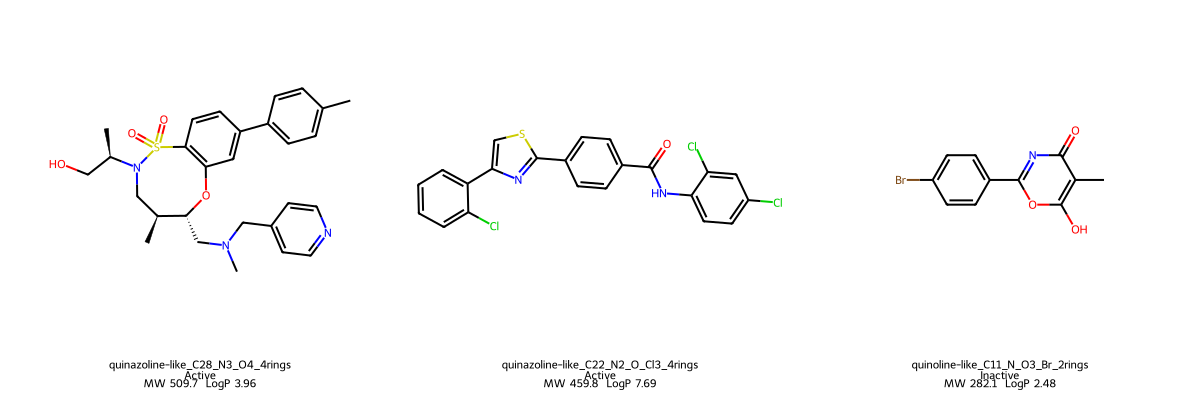

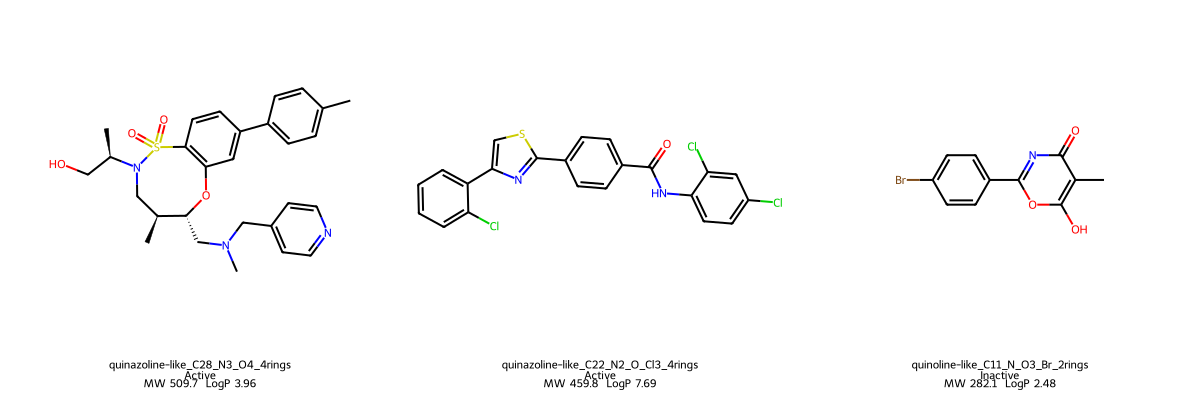

In [8]:
import visualize

visualize.draw_sample_molecules(dataset_df, n=config.VISUALIZE_N_MOLECULES)

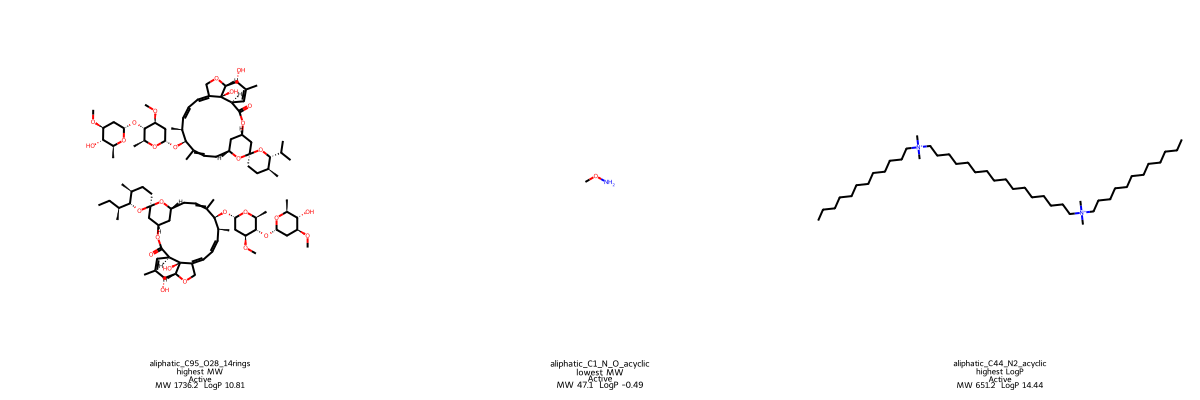

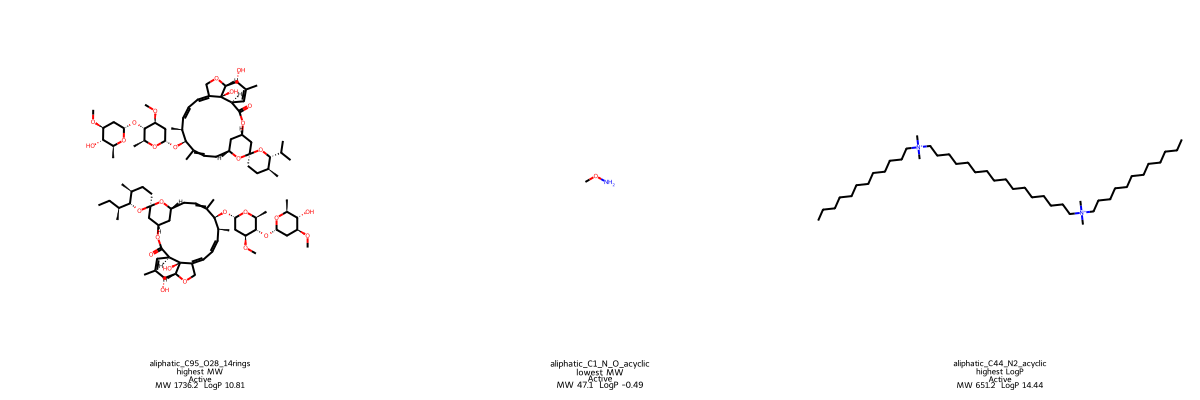

In [9]:
visualize.draw_extreme_molecules(dataset_df)


--- molecule 1/3 ---


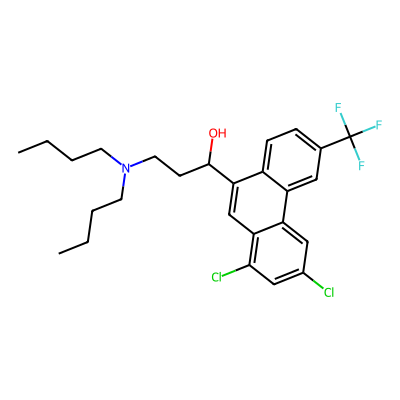

quinoline-like_C26_N_O_F3_Cl2_3rings (Active)
  SMILES: CCCCN(CCCC)CCC(O)c1cc2c(Cl)cc(Cl)cc2c2cc(C(F)(F)F)ccc12
  MolWt: 500.4320000000002
  LogP: 8.644300000000001
  TPSA: 23.47
  NumHDonors: 1
  NumHAcceptors: 2
  NumRotatableBonds: 10
  NumAromaticRings: 3
  HeavyAtomCount: 33
  Lipinski non-compliant (2 violations: MW > 500, LogP > 5)

--- molecule 2/3 ---


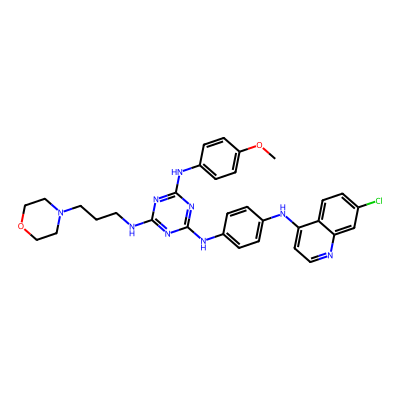

quinazoline-like_C32_N9_O2_Cl_6rings (Active)
  SMILES: COc1ccc(Nc2nc(NCCCN3CCOCC3)nc(Nc3ccc(Nc4ccnc5cc(Cl)ccc45)cc3)n2)cc1
  MolWt: 612.1380000000001
  LogP: 6.446800000000005
  TPSA: 121.38
  NumHDonors: 4
  NumHAcceptors: 11
  NumRotatableBonds: 12
  NumAromaticRings: 5
  HeavyAtomCount: 44
  Lipinski non-compliant (3 violations: MW > 500, LogP > 5, HBA > 10)

--- molecule 3/3 ---


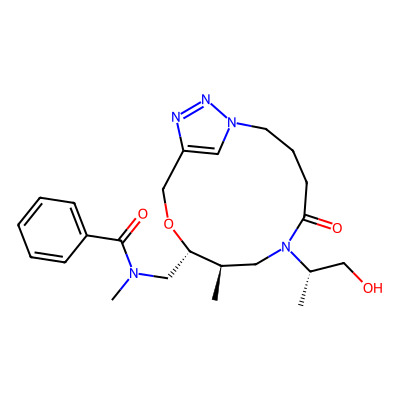

quinazoline-like_C23_N5_O4_3rings (Inactive)
  SMILES: C[C@@H]1CN(C(=O)CCCN2C=C(CO[C@H]1CN(C)C(=O)C3=CC=CC=C3)N=N2)[C@@H](C)CO
  MolWt: 443.5480000000001
  LogP: 1.5747999999999998
  TPSA: 100.79
  NumHDonors: 1
  NumHAcceptors: 7
  NumRotatableBonds: 5
  NumAromaticRings: 2
  HeavyAtomCount: 32
  Lipinski compliant


In [10]:
visualize.view_individual_molecules(dataset_df, n=config.VISUALIZE_N_MOLECULES)

## Cross-validation

Runs the descriptor-only baseline plus whichever GNNs `config.toml`
asked for, on the same stratified k-fold splits, then prints mean ± std
per model. This is what takes the longest — for a first pass, edit
`config.toml` above to use fewer folds and one model, confirm it runs,
then bump the numbers back up for a real run.


In [ ]:
import numpy as np
from graphs import build_graph_dataset
from models import GCNBaseline, GATNet, GCNTransformerNet, GATTransformerNet
from train import cross_validate_gnn
from baseline import cross_validate_all_baselines


MODEL_REGISTRY = {
    'gcn': lambda: GCNBaseline(),
    'gat': lambda: GATNet(),
    'gcn_transformer': lambda: GCNTransformerNet(),
    'gat_transformer': lambda: GATTransformerNet(),
}

cv_results = {}

if not config.SKIP_BASELINE:
    baseline_results = cross_validate_all_baselines(
        dataset_df, n_folds=config.N_FOLDS, seed=config.SEED, model_names=config.BASELINE_MODELS,
    )
    for name, metrics in baseline_results.items():
        cv_results[f'baseline_{name}'] = metrics

models_to_run = config.CV_MODELS or list(MODEL_REGISTRY.keys())
for name in models_to_run:
    print(f"\n=== {name} ===")
    cv_results[name] = cross_validate_gnn(
        MODEL_REGISTRY[name], dataset_df, build_graph_dataset,
        n_folds=config.N_FOLDS, seed=config.SEED, config=config.TRAIN_CONFIG,
    )


In [65]:
import json
with open(f'{config.OUTPUT_DIR}/cv_results_full.json', 'w') as f:
    json.dump({name: {k: list(v) for k, v in metrics.items()} for name, metrics in cv_results.items()}, f)
print(f"saved full cv_results to {config.OUTPUT_DIR}/cv_results_full.json")

saved full cv_results to test_results/cv_results_full.json


In [57]:
import pandas as pd

summary_rows = []
for name, metrics in cv_results.items():
    row = {'model': name}
    for metric, values in metrics.items():
        row[f'{metric}_mean'] = np.mean(values)
        row[f'{metric}_std'] = np.std(values)
    summary_rows.append(row)

summary_df = pd.DataFrame(summary_rows)
summary_df.to_csv(f'{config.OUTPUT_DIR}/cross_validation_summary.csv', index=False)


In [58]:


summary_df = pd.read_csv(f"{config.OUTPUT_DIR}/cross_validation_summary.csv")
summary_df


,model,accuracy_mean,accuracy_std,balanced_accuracy_mean,balanced_accuracy_std,auc_mean,auc_std,precision_mean,precision_std,recall_mean,recall_std,f1_mean,f1_std
0,baseline_random_forest,0.868348,0.005735,0.868348,0.005735,0.930754,0.004267,0.846415,0.008261,0.900118,0.003761,0.872420,0.005084
1,baseline_logistic_regression,0.844620,0.004752,0.844620,0.004752,0.912026,0.003857,0.858401,0.007326,0.825463,0.003292,0.841596,0.004429
2,baseline_linear_svm,0.843082,0.004736,0.843082,0.004736,0.911102,0.003813,0.856854,0.008111,0.823886,0.002631,0.840027,0.004228
3,baseline_gradient_boosting,0.875089,0.004979,0.875089,0.004979,0.938496,0.003396,0.859997,0.006257,0.896098,0.005076,0.877664,0.004718
4,baseline_knn,0.857903,0.004595,0.857903,0.004595,0.928859,0.004063,0.851763,0.008492,0.866772,0.003222,0.859171,0.003876
5,gcn,0.883445,0.005055,0.883445,0.005055,0.946346,0.003624,0.867002,0.007547,0.905952,0.006706,0.886016,0.004753
6,gat,0.876862,0.006383,0.876862,0.006383,0.944902,0.003944,0.875543,0.008872,0.878912,0.019370,0.877030,0.007687
7,gcn_transformer,0.859992,0.015834,0.859992,0.015834,0.931157,0.010501,0.856460,0.010789,0.865274,0.038260,0.860338,0.018732
8,gat_transformer,0.872921,0.003701,0.872921,0.003701,0.939330,0.003941,0.867016,0.011584,0.881435,0.016293,0.873959,0.004342


In [11]:
### Load
import pandas as pd
import json
with open(f'{config.OUTPUT_DIR}/cv_results_full.json') as f:
    cv_results = json.load(f)
print(f"loaded cv_results for: {list(cv_results.keys())}")

loaded cv_results for: ['baseline_random_forest', 'baseline_logistic_regression', 'baseline_linear_svm', 'baseline_gradient_boosting', 'baseline_knn', 'gcn', 'gat', 'gcn_transformer', 'gat_transformer']


In [12]:
cv_results

{'baseline_random_forest': {'accuracy': [0.8734726054394955,
   0.8648009459992116,
   0.8590855340953882,
   0.869925108395743,
   0.8744580212849823],
  'balanced_accuracy': [0.8734726054394955,
   0.8648009459992116,
   0.8590855340953882,
   0.8699251083957431,
   0.8744580212849823],
  'auc': [0.9337617995487829,
   0.9240661932216752,
   0.9273121227201238,
   0.9342028090682807,
   0.9344291789361362],
  'precision': [0.8528864059590316,
   0.8418913926856298,
   0.8344346549192364,
   0.8449099595736862,
   0.8579502637528259],
  'recall': [0.9026409144659047,
   0.8983050847457628,
   0.8959400867165944,
   0.9061884115096571,
   0.8975167520693733],
  'f1': [0.8770585982382229,
   0.8691838291380626,
   0.8640942786542483,
   0.8744769874476988,
   0.8772876131766519]},
 'baseline_logistic_regression': {'accuracy': [0.8535672053606622,
   0.8452897122585731,
   0.8423334647221127,
   0.8405597162002365,
   0.841348048876626],
  'balanced_accuracy': [0.8535672053606622,
   0.8

## Train and save final models

Implements: 80% train / 20% test outer split, 5-fold CV inside the 80%
for hyperparameter tuning (GNNs only — the classical baselines fit
directly, no tuning needed for them), then one final model per
architecture trained on the full 80% and evaluated exactly once on the
untouched 20% test set.

**This is what you cite as your reported test performance per
architecture.** The cross-validated numbers from the section above are
a separate, complementary claim (how robust is the approach across
different splits) — report both, and say which is which in your
methods section.

Saves everything: `trained_models/{name}_best.pth`,
`training_history/{name}_history.pkl`,
`test_results/{name}_tuning_results.csv`,
`test_results/{name}_results.pkl`.

In [14]:
import pickle
import tune
from models import BASELINE_REGISTRY

outer_train_df, outer_test_df = tune.outer_split(dataset_df, test_size=config.TUNE_TEST_SIZE, seed=config.SEED)
print(f"outer split: {len(outer_train_df)} train (80%), {len(outer_test_df)} test (20%, held out until final eval)")

final_results = {}

print("--- classical baselines (fit directly on the 80%, no tuning) ---")
from data_prep import prepare_two_way_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, balanced_accuracy_score

baseline_train_df, baseline_test_df, baseline_descriptor_cols, _ = prepare_two_way_split(outer_train_df, outer_test_df, config.SEED)
X_train_final = baseline_train_df[baseline_descriptor_cols].values
y_train_final = baseline_train_df['Labels'].values
X_test_final = baseline_test_df[baseline_descriptor_cols].values
y_test_final = baseline_test_df['Labels'].values

for baseline_name, build_baseline in BASELINE_REGISTRY.items():
    print(f"training {baseline_name}")
    baseline_model = build_baseline(config.SEED)
    if hasattr(baseline_model, 'n_neighbors'):
        baseline_model.n_neighbors = max(1, min(baseline_model.n_neighbors, len(X_train_final) - 1))

    try:
        baseline_model.fit(X_train_final, y_train_final)
        preds = baseline_model.predict(X_test_final)
        probs = baseline_model.predict_proba(X_test_final)[:, 1]
        baseline_result = {
            'accuracy': accuracy_score(y_test_final, preds),
            'balanced_accuracy': balanced_accuracy_score(y_test_final, preds),
            'auc': roc_auc_score(y_test_final, probs),
            'precision': precision_score(y_test_final, preds, zero_division=0),
            'recall': recall_score(y_test_final, preds, zero_division=0),
            'f1': f1_score(y_test_final, preds, zero_division=0),
            'predictions': preds,
            'true_labels': y_test_final,
            'probabilities': probs,
        }
    except Exception as e:
        print(f"  {baseline_name} failed ({e}), skipping")
        continue

    result_path = f'{config.OUTPUT_DIR}/baseline_{baseline_name}_results.pkl'
    with open(result_path, 'wb') as f:
        pickle.dump(baseline_result, f)
    print(f"  test acc={baseline_result['accuracy']:.3f} auc={baseline_result['auc']:.3f} f1={baseline_result['f1']:.3f} -> {result_path}")

    final_results[f'baseline_{baseline_name}'] = baseline_result

print("--- GNNs: 5-fold CV inside the 80% for tuning, then one final fit + one final test ---")
CHECKPOINT_NAMES = {
    'gcn': 'gnn_model',
    'gat': 'gat_model',
    'gcn_transformer': 'gcn_transformer_model',
    'gat_transformer': 'gat_transformer_model',
}

final_models = {}
tuning_results = {}

for key, model_fn in MODEL_REGISTRY.items():
    name = CHECKPOINT_NAMES[key]
    model_class = type(model_fn())

    print(f"=== {name}: tuning (5-fold CV inside the 80% train) ===")
    tuning_results_df, best_params = tune.tune_hyperparameters(
        model_class, outer_train_df, n_folds=config.TUNE_FOLDS, seed=config.SEED,
        tuning_epochs=config.TUNE_EPOCHS, tuning_patience=config.TUNE_PATIENCE,
    )
    print(f"best params for {name}: {best_params}")
    tuning_results_df.to_csv(f'{config.OUTPUT_DIR}/{name}_tuning_results.csv', index=False)
    tuning_results[name] = tuning_results_df

    print(f"=== {name}: final fit on full 80%, one evaluation on the 20% test ===")
    model, history, result = tune.train_with_best_params(
        model_class, best_params, outer_train_df, outer_test_df,
        seed=config.SEED, save_as=name,
    )
    final_models[key] = model
    final_results[name] = result

    with open(f'{config.OUTPUT_DIR}/{name}_results.pkl', 'wb') as f:
        pickle.dump(result, f)
    print(f"{name}: test acc={result['accuracy']:.3f} auc={result['auc']:.3f} f1={result['f1']:.3f}")


outer split: 20296 train (80%), 5074 test (20%, held out until final eval)
--- classical baselines (fit directly on the 80%, no tuning) ---
kept 74/104 descriptors (train split only, r >= 0.85 dropped)
training random_forest
  test acc=0.872 auc=0.933 f1=0.876 -> test_results/baseline_random_forest_results.pkl
training logistic_regression
  test acc=0.848 auc=0.915 f1=0.846 -> test_results/baseline_logistic_regression_results.pkl
training linear_svm
  test acc=0.847 auc=0.913 f1=0.845 -> test_results/baseline_linear_svm_results.pkl
training gradient_boosting
  test acc=0.878 auc=0.938 f1=0.881 -> test_results/baseline_gradient_boosting_results.pkl
training knn
  test acc=0.854 auc=0.927 f1=0.854 -> test_results/baseline_knn_results.pkl
--- GNNs: 5-fold CV inside the 80% for tuning, then one final fit + one final test ---
=== gnn_model: tuning (5-fold CV inside the 80% train) ===
kept 73/104 descriptors (train split only, r >= 0.85 dropped)
built 13530/13530 graphs
built 6766/6766 graph

In [14]:
### Load all final models and results from disk, without retraining, for comparison/analysis

import json
import pickle
import tune
import os
import torch
from torch_geometric.loader import DataLoader
from models import GCNBaseline, GATNet, GCNTransformerNet, GATTransformerNet, BASELINE_REGISTRY
from train import load_checkpoint
from data_prep import outer_split
from tune import prepare_final_split
from graphs import build_graph_dataset

CHECKPOINT_NAMES = {
    'gcn': 'gnn_model',
    'gat': 'gat_model',
    'gcn_transformer': 'gcn_transformer_model',
    'gat_transformer': 'gat_transformer_model',
}
MODEL_CLASSES = {
    'gcn': GCNBaseline,
    'gat': GATNet,
    'gcn_transformer': GCNTransformerNet,
    'gat_transformer': GATTransformerNet,
}

outer_train_df, outer_test_df = outer_split(dataset_df, test_size=config.TUNE_TEST_SIZE, seed=config.SEED)
train_df, val_df, test_df, descriptor_cols, _ = prepare_final_split(outer_train_df, outer_test_df, config.SEED)
explain_test_graphs = build_graph_dataset(test_df, descriptor_cols)

final_models = {}
final_results = {}
tuning_results = {}

for key, model_class in MODEL_CLASSES.items():
    name = CHECKPOINT_NAMES[key]

    with open(f'trained_models/{name}_best_params.json') as f:
        params = json.load(f)
    m = model_class(**params)
    dummy_batch = next(iter(DataLoader(explain_test_graphs[:4], batch_size=4))).to(config.DEVICE)
    m = m.to(config.DEVICE)
    with torch.no_grad():
        _ = m(dummy_batch)
    final_models[key] = load_checkpoint(m, name)

    with open(f'{config.OUTPUT_DIR}/{name}_results.pkl', 'rb') as f:
        final_results[name] = pickle.load(f)

    tuning_results[name] = pd.read_csv(f'{config.OUTPUT_DIR}/{name}_tuning_results.csv')
    print(f"loaded {name}")

for baseline_name in BASELINE_REGISTRY.keys():
    path = f'{config.OUTPUT_DIR}/baseline_{baseline_name}_results.pkl'
    if os.path.exists(path):
        with open(path, 'rb') as f:
            final_results[f'baseline_{baseline_name}'] = pickle.load(f)

print("all loaded, no retraining")

kept 73/104 descriptors (train split only, r >= 0.85 dropped)
built 5074/5074 graphs
loaded trained_models/gnn_model_best.pth
loaded gnn_model
loaded trained_models/gat_model_best.pth
loaded gat_model
loaded trained_models/gcn_transformer_model_best.pth
loaded gcn_transformer_model
loaded trained_models/gat_transformer_model_best.pth
loaded gat_transformer_model
all loaded, no retraining


## Compare all models

Bar charts across all models (five classical baselines + three GNNs),
with error bars from the cross-validation folds, plus:
- ROC curves from the held-out 20% test set saved above
- train/validation loss, accuracy, and AUC curves per GNN
- confusion matrices for every model
- hyperparameter tuning results per GNN (the "not complicated" version —
  a handful of combinations, not an exhaustive search)

This is what you'd actually put in a paper — figures that make clear
whether the GNNs earned their added complexity over the classical
baselines, rather than a printed list of numbers scattered across cells.

In [15]:
import compare

comparison_table = compare.comparison_table(cv_results)
comparison_table.to_csv(f'{config.OUTPUT_DIR}/model_comparison_table.csv', index=False)


In [16]:
# Load the comparison table and display it

comparison_table = pd.read_csv(f"{config.OUTPUT_DIR}/model_comparison_table.csv")
comparison_table

,model,type,accuracy_mean,accuracy_std,balanced_accuracy_mean,balanced_accuracy_std,auc_mean,auc_std,precision_mean,precision_std,recall_mean,recall_std,f1_mean,f1_std
0,GCN,GNN,0.883445,0.005055,0.883445,0.005055,0.946346,0.003624,0.867002,0.007547,0.905952,0.006706,0.886016,0.004753
1,GAT,GNN,0.876862,0.006383,0.876862,0.006383,0.944902,0.003944,0.875543,0.008872,0.878912,0.019370,0.877030,0.007687
2,GAT-Transformer,GNN,0.872921,0.003701,0.872921,0.003701,0.939330,0.003941,0.867016,0.011584,0.881435,0.016293,0.873959,0.004342
3,Gradient Boosting,baseline,0.875089,0.004979,0.875089,0.004979,0.938496,0.003396,0.859997,0.006257,0.896098,0.005076,0.877664,0.004718
4,GCN-Transformer,GNN,0.859992,0.015834,0.859992,0.015834,0.931157,0.010501,0.856460,0.010789,0.865274,0.038260,0.860338,0.018732
5,Random Forest,baseline,0.868348,0.005735,0.868348,0.005735,0.930754,0.004267,0.846415,0.008261,0.900118,0.003761,0.872420,0.005084
6,k-NN,baseline,0.857903,0.004595,0.857903,0.004595,0.928859,0.004063,0.851763,0.008492,0.866772,0.003222,0.859171,0.003876
7,Logistic Regression,baseline,0.844620,0.004752,0.844620,0.004752,0.912026,0.003857,0.858401,0.007326,0.825463,0.003292,0.841596,0.004429
8,Linear SVM,baseline,0.843082,0.004736,0.843082,0.004736,0.911102,0.003813,0.856854,0.008111,0.823886,0.002631,0.840027,0.004228


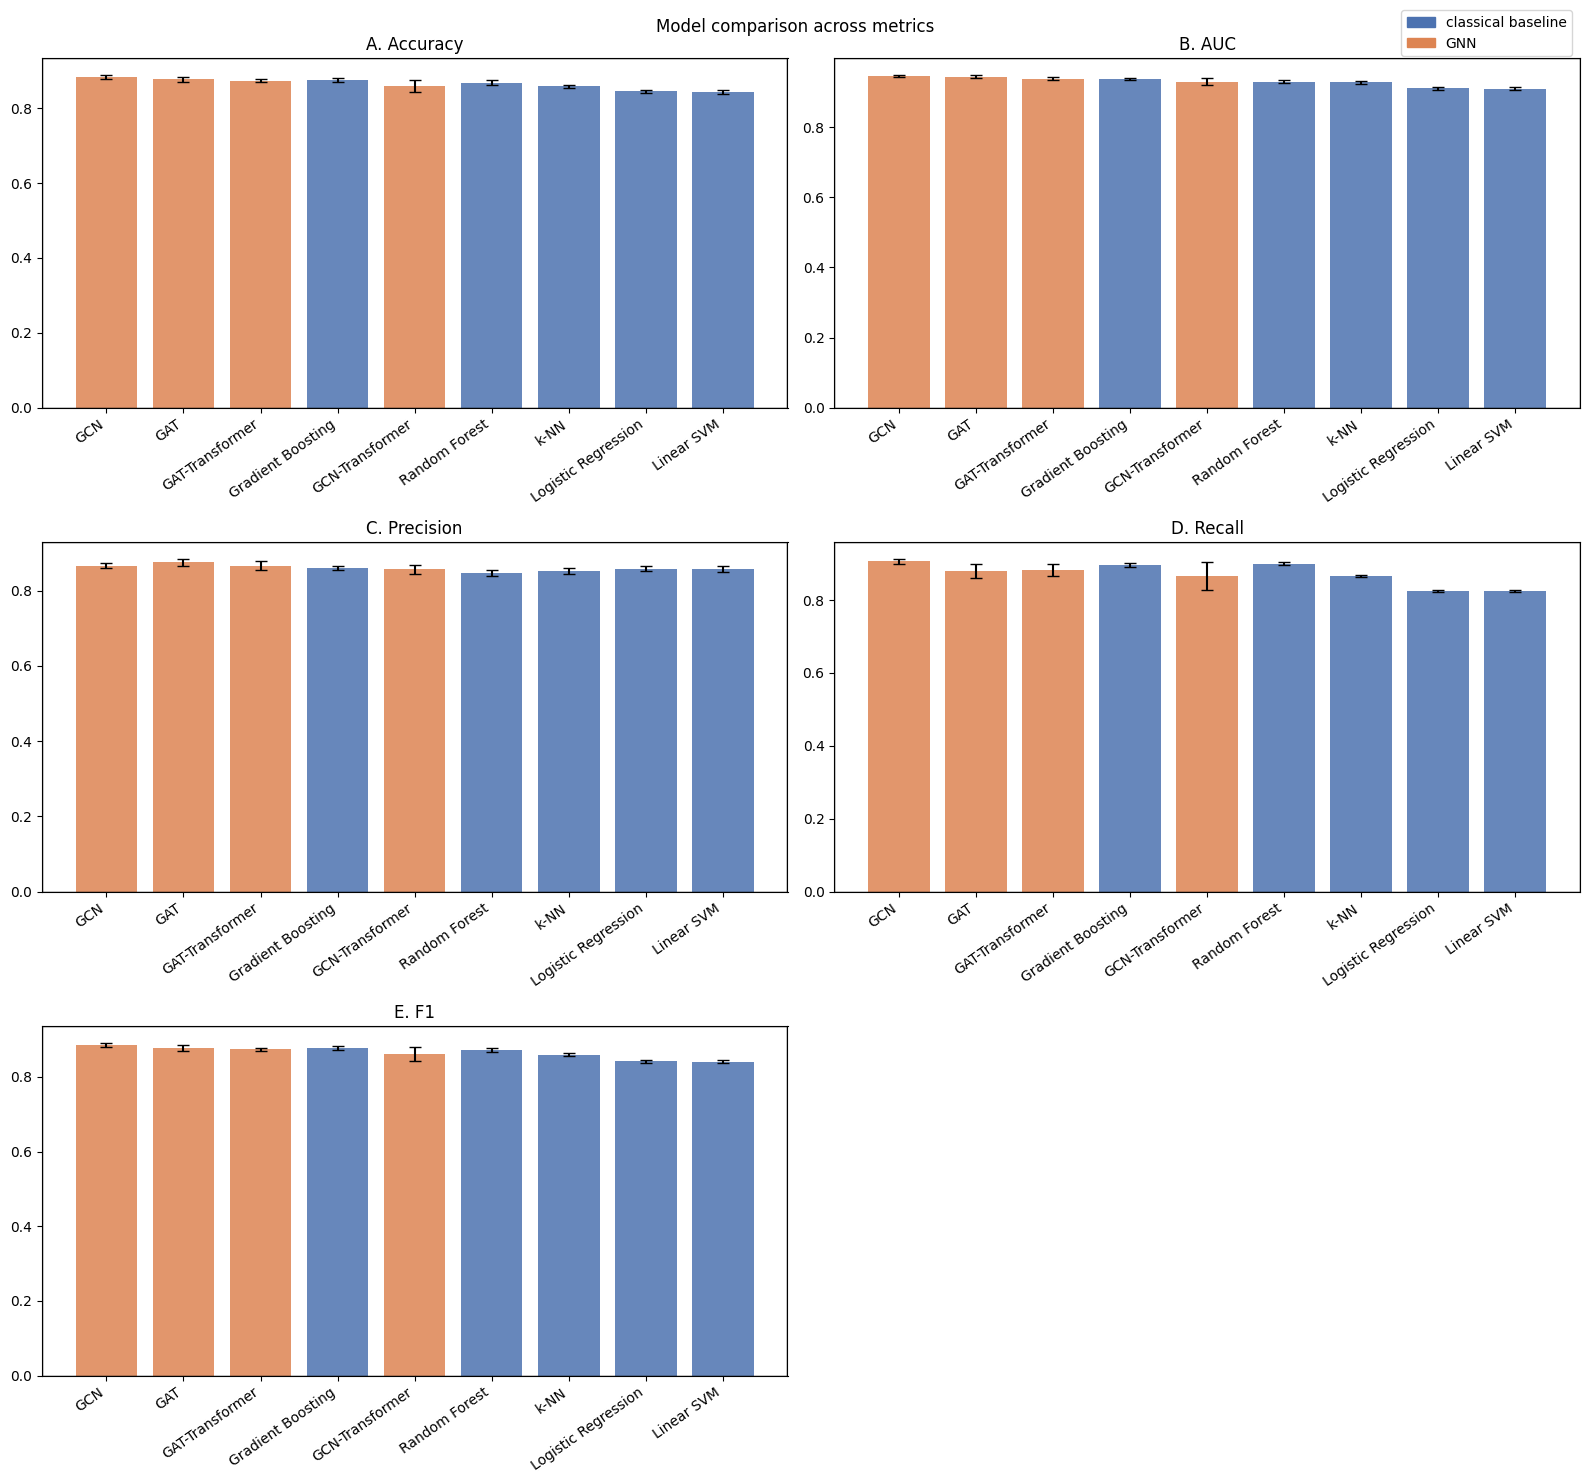

saved 5-metric comparison (A-E) to figures/metrics_comparison.pdf


,model,type,accuracy_mean,accuracy_std,balanced_accuracy_mean,balanced_accuracy_std,auc_mean,auc_std,precision_mean,precision_std,recall_mean,recall_std,f1_mean,f1_std
0,GCN,GNN,0.883445,0.005055,0.883445,0.005055,0.946346,0.003624,0.867002,0.007547,0.905952,0.006706,0.886016,0.004753
1,GAT,GNN,0.876862,0.006383,0.876862,0.006383,0.944902,0.003944,0.875543,0.008872,0.878912,0.019370,0.877030,0.007687
2,GAT-Transformer,GNN,0.872921,0.003701,0.872921,0.003701,0.939330,0.003941,0.867016,0.011584,0.881435,0.016293,0.873959,0.004342
3,Gradient Boosting,baseline,0.875089,0.004979,0.875089,0.004979,0.938496,0.003396,0.859997,0.006257,0.896098,0.005076,0.877664,0.004718
4,GCN-Transformer,GNN,0.859992,0.015834,0.859992,0.015834,0.931157,0.010501,0.856460,0.010789,0.865274,0.038260,0.860338,0.018732
5,Random Forest,baseline,0.868348,0.005735,0.868348,0.005735,0.930754,0.004267,0.846415,0.008261,0.900118,0.003761,0.872420,0.005084
6,k-NN,baseline,0.857903,0.004595,0.857903,0.004595,0.928859,0.004063,0.851763,0.008492,0.866772,0.003222,0.859171,0.003876
7,Logistic Regression,baseline,0.844620,0.004752,0.844620,0.004752,0.912026,0.003857,0.858401,0.007326,0.825463,0.003292,0.841596,0.004429
8,Linear SVM,baseline,0.843082,0.004736,0.843082,0.004736,0.911102,0.003813,0.856854,0.008111,0.823886,0.002631,0.840027,0.004228


In [17]:

import compare
compare.plot_all_metrics_comparison(cv_results)

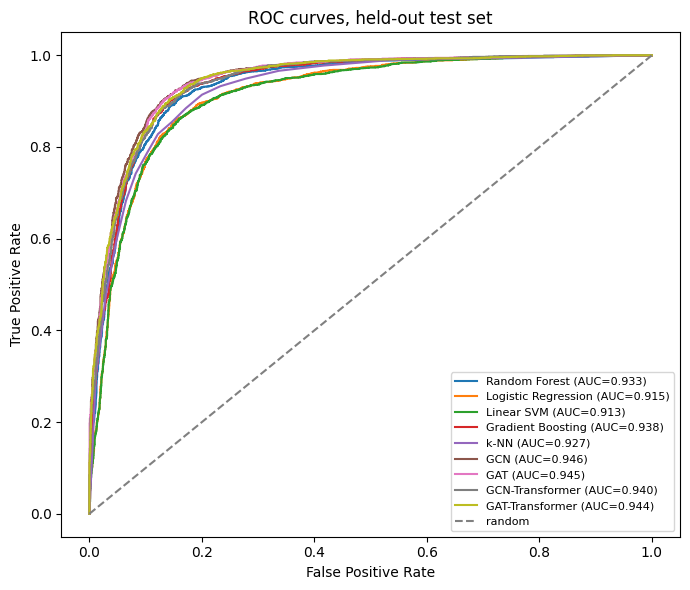

In [20]:
# uses the *_results.pkl files saved in the section above (held-out test
# set predictions), not cv_results -- cv doesn't keep per-molecule
# probabilities, only the fold-level summary metrics
compare.plot_roc_curves()

In [18]:
# train vs. validation loss/AUC per epoch for each GNN -- the gap between
# the two lines is what tells you whether a model is overfitting, not
# either line on its own
# compare.plot_all_training_curves()

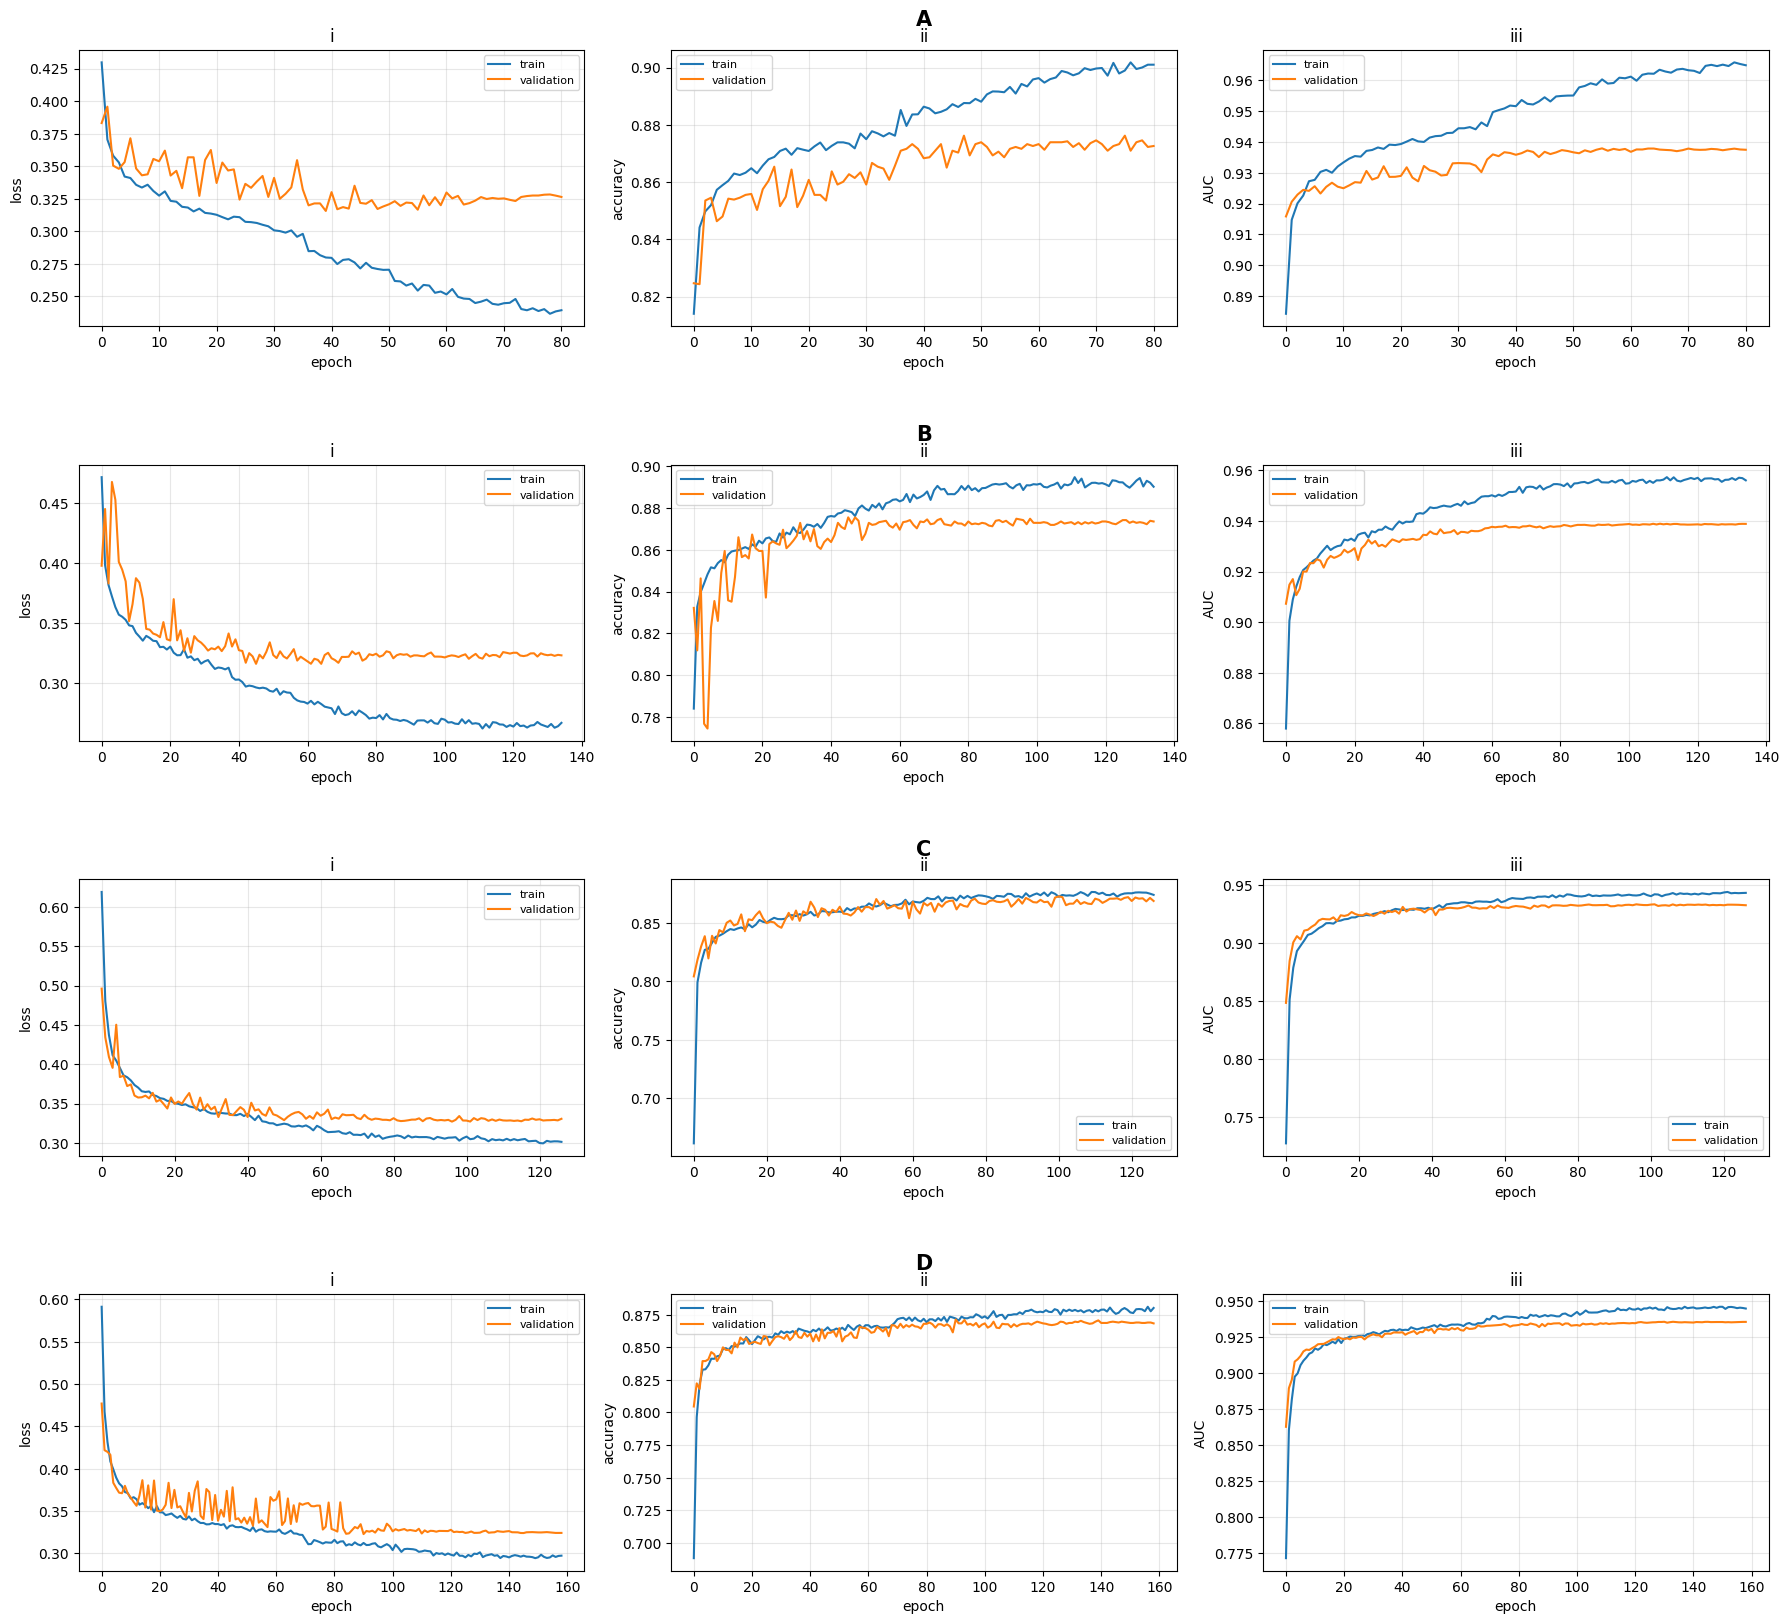

saved training curves for 4 models to figures/training_curves.pdf


'figures/training_curves.pdf'

In [16]:
# train vs. validation loss/AUC per epoch for each GNN -- the gap between
# the two lines is what tells you whether a model is overfitting, not
# either line on its own
compare.save_training_curves_pdf()

## Confusion matrices, all models

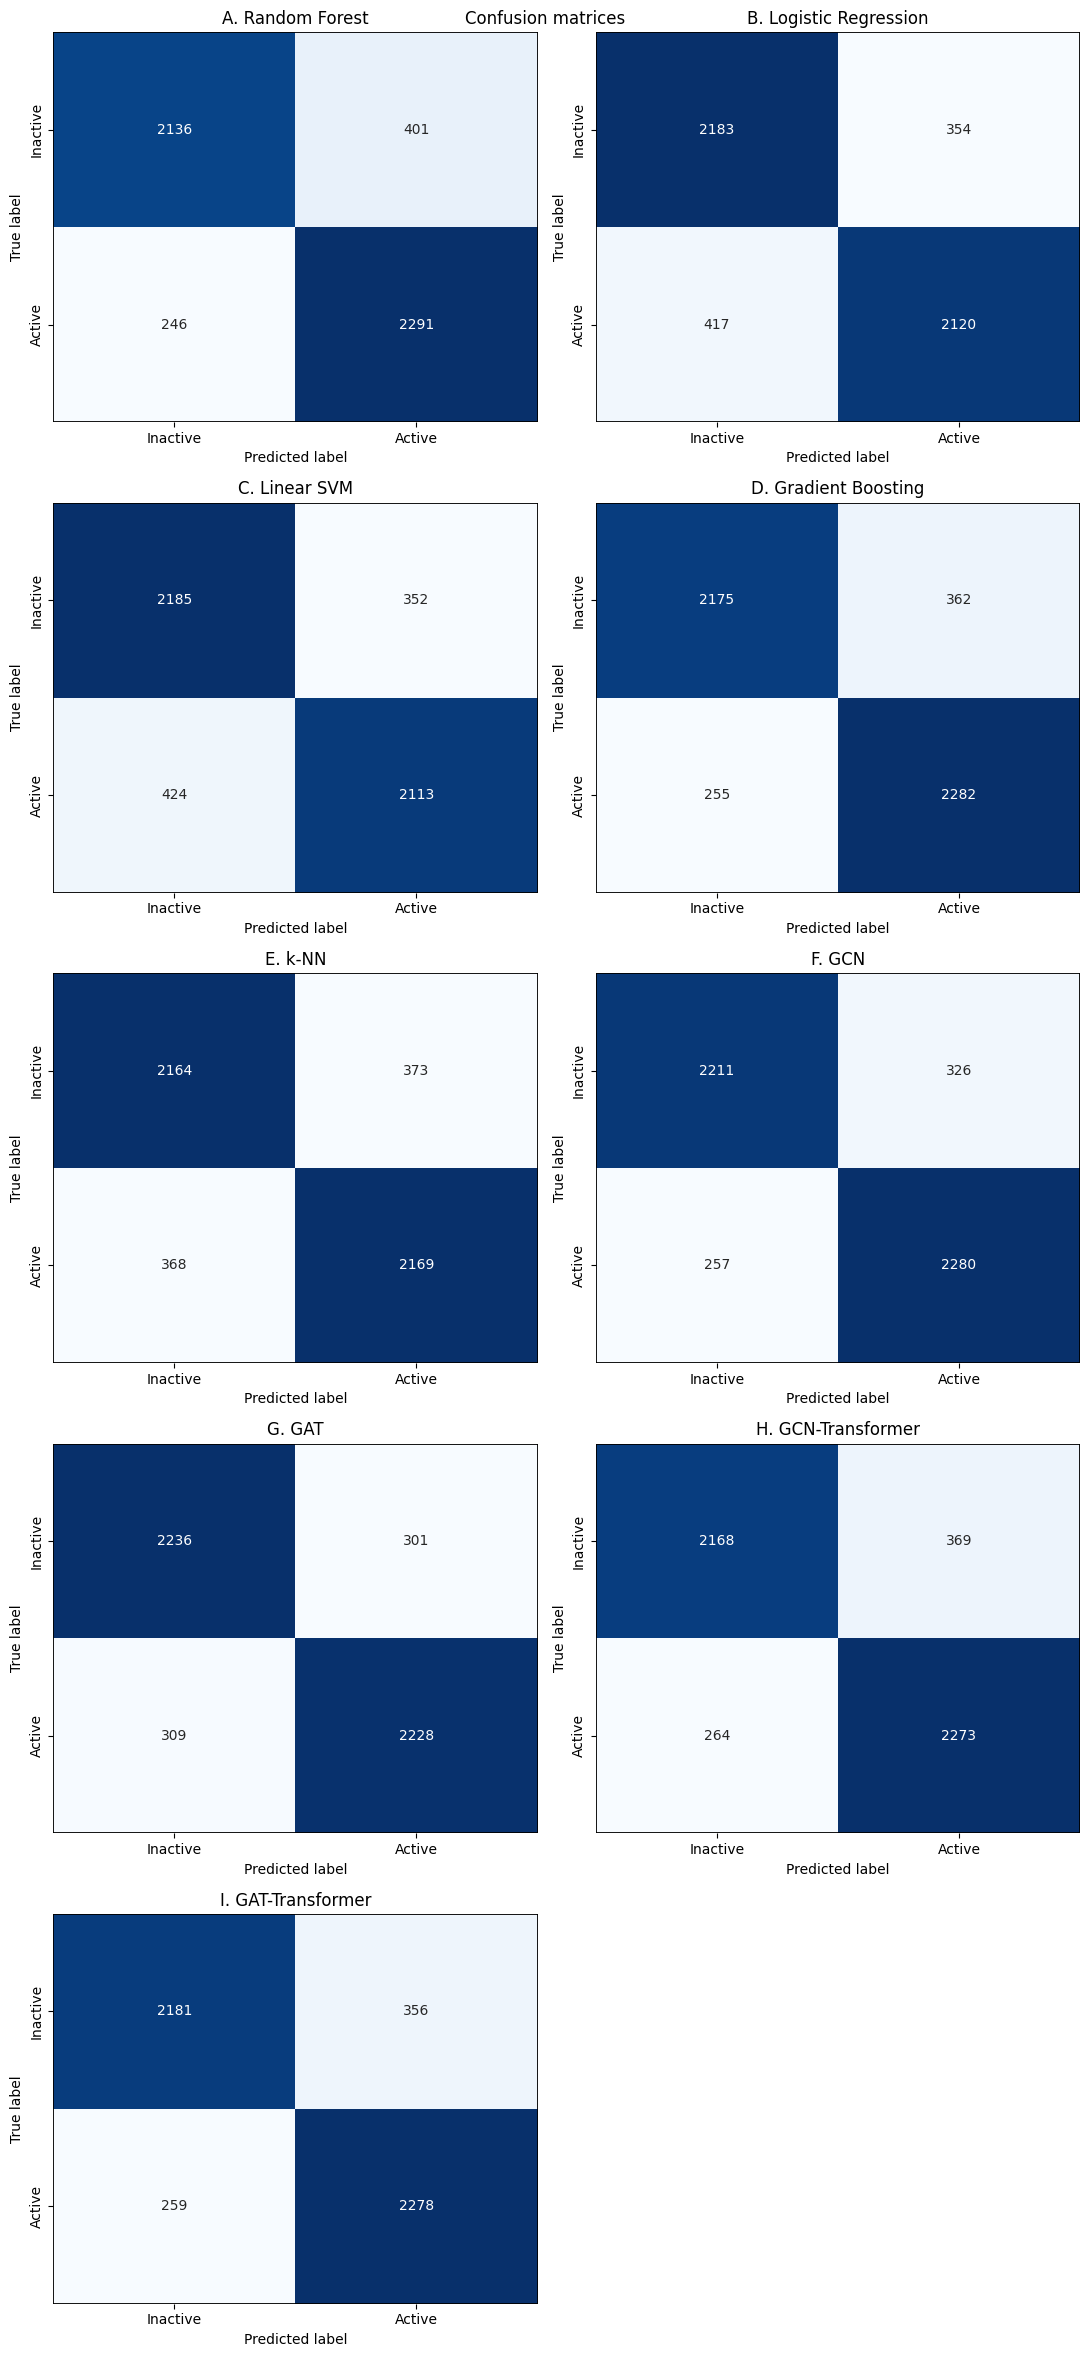

saved 9 confusion matrices (A-I) to figures/confusion_matrices.pdf


'figures/confusion_matrices.pdf'

In [17]:
compare.plot_all_confusion_matrices()

## Balanced confusion matrices (supplementary, not the primary result)

Same predictions as above, randomly subsampled so the majority class
(Inactive) is cut down to match the minority class (Active) count.
This does **not** replace the confusion matrices above, and it does
**not** mean the model was retrained or the test set was rebalanced —
it's the same test-set predictions, just re-tallied on a random
balanced subset for a narrower question: "does the pattern hold when
class sizes are equal." Report the matrices above as your primary
result; use these only as a supplementary check.

In [61]:
# compare.plot_all_balanced_confusion_matrices()

## Hyperparameter tuning results

One bar chart per GNN architecture — mean validation AUC (with std error bars across the tuning folds) for each hyperparameter combination tried in the section above.

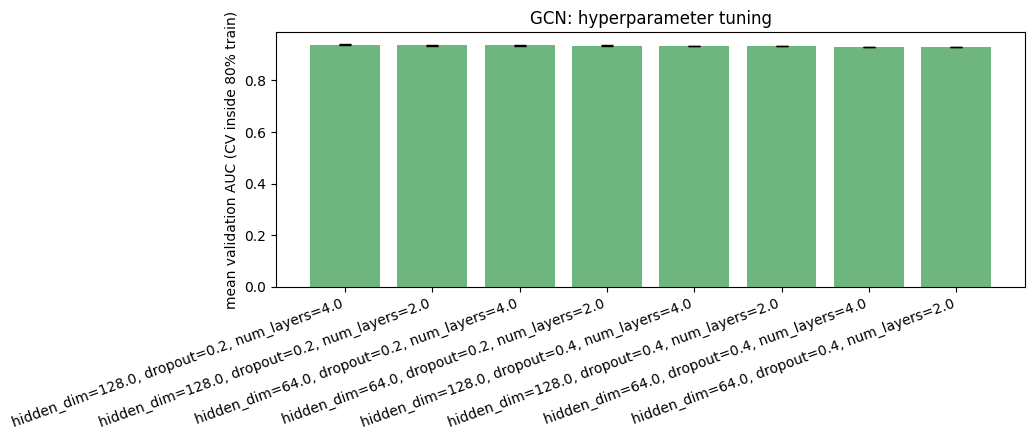

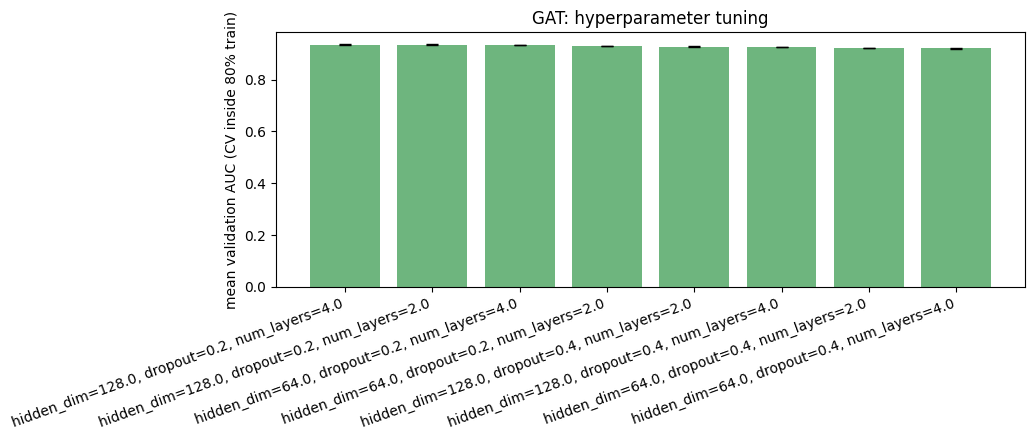

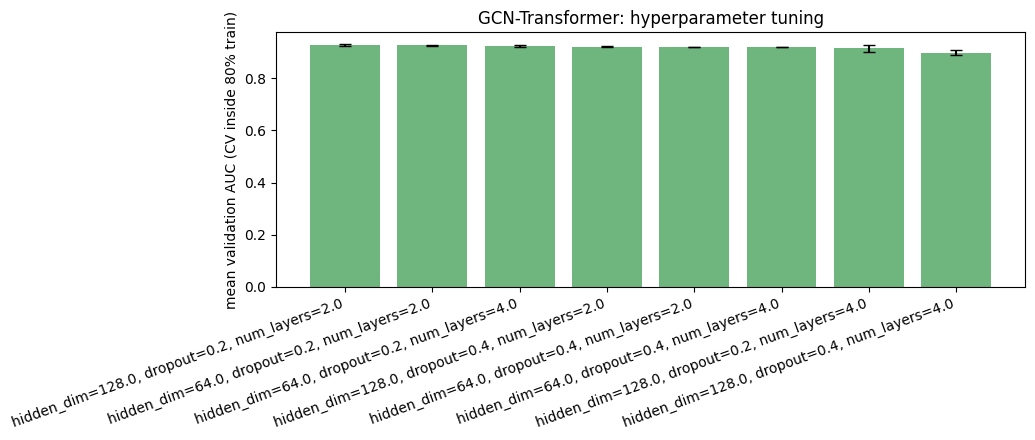

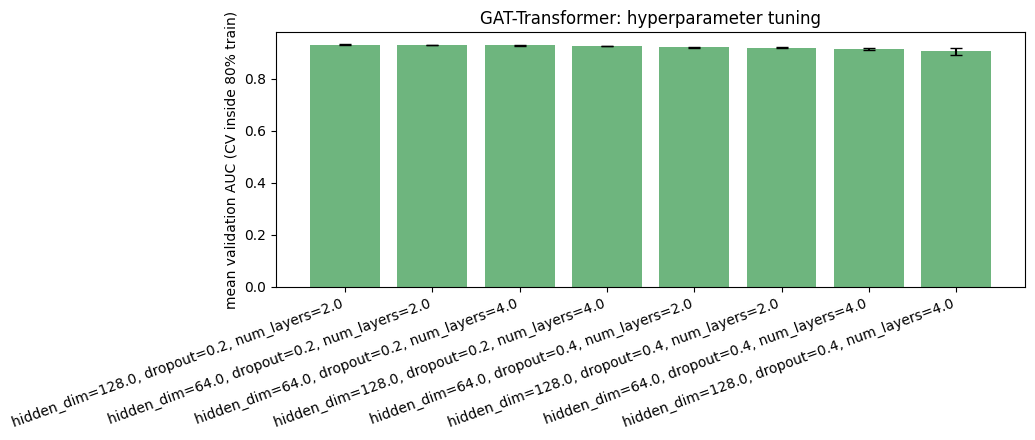

In [19]:
for name, results_df in tuning_results.items():
    compare.plot_tuning_results(results_df, model_name=name, save_path=f'{config.FIGURE_DIR}/{name}_tuning.png')

## Explainability

Reuses the `gat_transformer_model` trained and saved in the section above (no need to retrain), and runs four methods on the real trained graph structure — none of them flatten the molecule into an edgeless stand-in, so what you get back reflects how the model actually used the graph:

- **GNNExplainer** — learns node/edge importance masks directly
- **Integrated Gradients** — attributes the prediction back through the network via a path integral
- **Feature Ablation** — zeroes each feature one at a time and measures the effect (slower, doesn't rely on smooth gradients)
- **Saliency** — plain gradient of output w.r.t. input (cheapest, also the noisiest — treat it as a quick first look, not the final word)

Worth checking: do these four roughly agree on which atom features matter most? If they don't, that's worth digging into rather than picking whichever one supports the story you wanted.

In [18]:
from explain import (
    explain_molecule_set, integrated_gradients_on_batch, feature_ablation_on_batch, saliency_on_batch,
    shap_on_batch, integrated_gradients_descriptors, feature_ablation_descriptors, saliency_descriptors,
    gnnexplainer_descriptors, shap_descriptors,
)
from torch_geometric.loader import DataLoader

# reuse the gat_transformer_model trained and saved in the section above --
# no retraining. explain_test_graphs comes from the exact same split
# (outer 80/20 + inner 85/15) that model was actually trained on.
explain_model = final_models['gat_transformer']
explain_train_df, explain_val_df, explain_test_df, explain_descriptor_cols, _ = tune.prepare_final_split(
    outer_train_df, outer_test_df, config.SEED
)
explain_test_graphs = build_graph_dataset(explain_test_df, explain_descriptor_cols)

explain_device = next(explain_model.parameters()).device
print(f"explaining on device: {explain_device}")

holdout_metrics = final_results['gat_transformer_model']
print(f"holdout test: acc={holdout_metrics['accuracy']:.3f} auc={holdout_metrics['auc']:.3f} f1={holdout_metrics['f1']:.3f}")


kept 73/104 descriptors (train split only, r >= 0.85 dropped)
built 5074/5074 graphs
explaining on device: cpu
holdout test: acc=0.879 auc=0.944 f1=0.881


In [19]:
from torch_geometric.loader import DataLoader

n = config.EXPLAIN_N_MOLECULES
sample_batch = next(iter(DataLoader(explain_test_graphs[:n], batch_size=n))).to(explain_device)

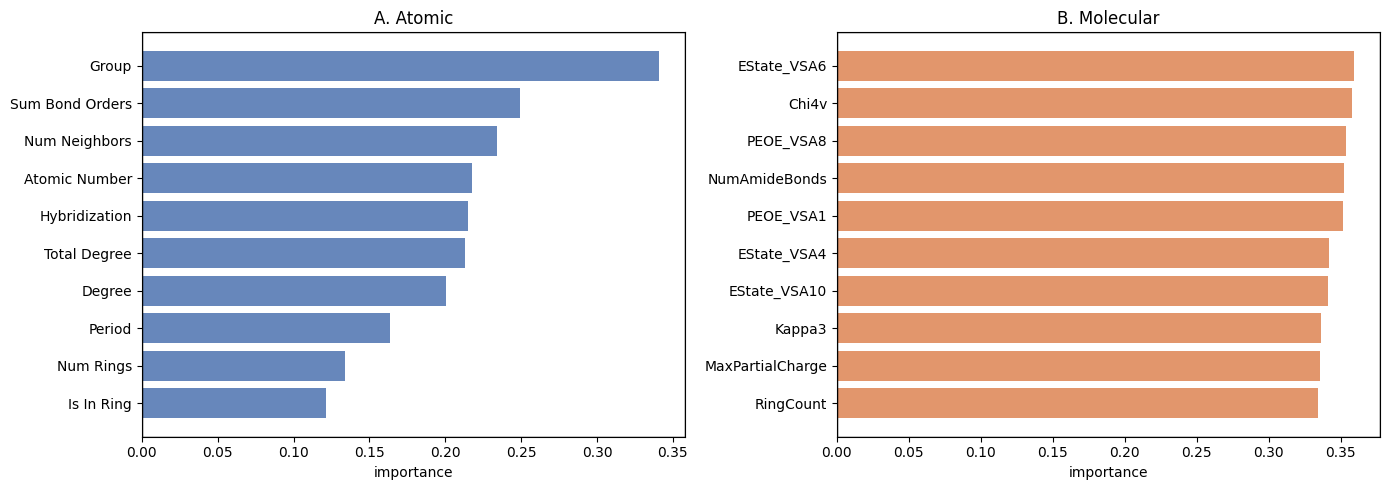

saved 2-method feature importance comparison (A-B) to figures/gnnexplainer_atomic_vs_molecular.pdf
GNNExplainer — top atom features:
           feature  importance
0            Group    0.340925
1  Sum Bond Orders    0.248938
2    Num Neighbors    0.234159
3    Atomic Number    0.217881
4    Hybridization    0.215178
5     Total Degree    0.212830
6           Degree    0.200667
7           Period    0.163393
8        Num Rings    0.134228
9       Is In Ring    0.121571

GNNExplainer-style — top descriptors:


,descriptor,importance
0,EState_VSA6,0.359407
1,Chi4v,0.357749
2,PEOE_VSA8,0.353763
3,NumAmideBonds,0.352290
4,PEOE_VSA1,0.351796
5,EState_VSA4,0.341818
6,EState_VSA10,0.341183
7,Kappa3,0.336540
8,MaxPartialCharge,0.335713
9,RingCount,0.334321


In [20]:
gnnexplainer_df = explain_molecule_set(explain_model, explain_test_graphs, explain_device, max_molecules=n)
gnnexplainer_df.to_csv(f'{config.OUTPUT_DIR}/gnnexplainer_importance.csv', index=False)

desc_gnnexplainer_df = gnnexplainer_descriptors(explain_model, sample_batch, explain_descriptor_cols)
desc_gnnexplainer_df.to_csv(f'{config.OUTPUT_DIR}/descriptor_gnnexplainer_importance.csv', index=False)

compare.save_feature_importance_pdf(
    {'Atomic': gnnexplainer_df.rename(columns={'feature': 'name'}),
     'Molecular': desc_gnnexplainer_df.rename(columns={'descriptor': 'name'})},
    output_path=f'{config.FIGURE_DIR}/gnnexplainer_atomic_vs_molecular.pdf',
    feature_col='name',
)

print("GNNExplainer — top atom features:")
print(gnnexplainer_df.head(10))
print("\nGNNExplainer-style — top descriptors:")
desc_gnnexplainer_df.head(10)

/opt/miniconda3/envs/DA/lib/python3.10/site-packages/captum/attr/_utils/batching.py:51: UserWarning: Internal batch size cannot be less than the number of input examples. Defaulting to internal batch size of 662 equal to the number of examples.
  warnings.warn(


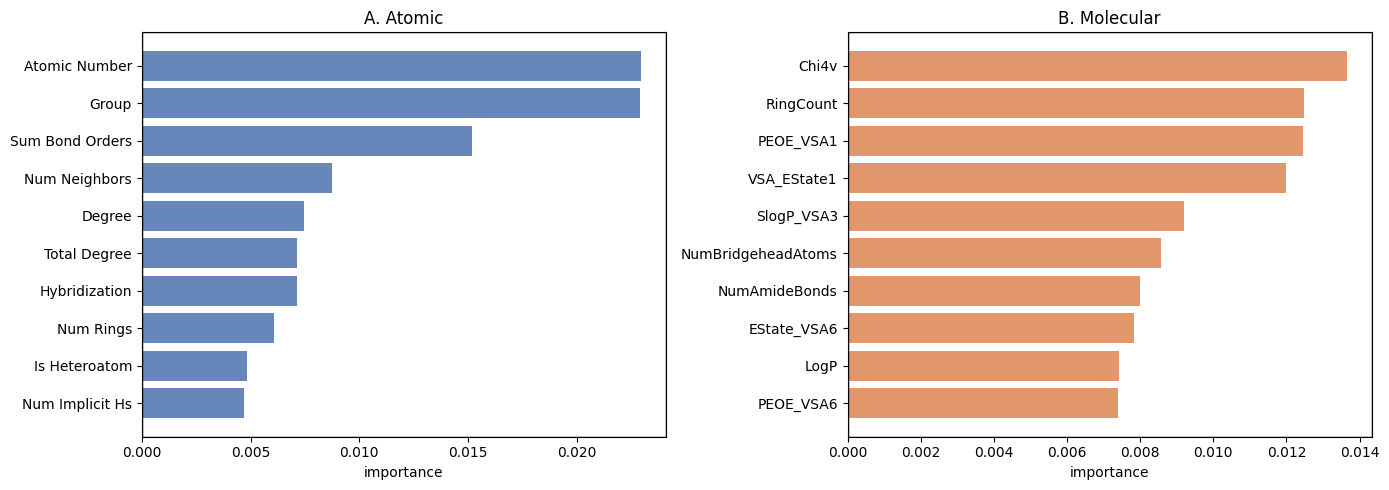

saved 2-method feature importance comparison (A-B) to figures/integrated_gradients_atomic_vs_molecular.pdf
Integrated Gradients — top atom features:
           feature  importance
0    Atomic Number    0.022968
1            Group    0.022902
2  Sum Bond Orders    0.015206
3    Num Neighbors    0.008726
4           Degree    0.007444
5     Total Degree    0.007138
6    Hybridization    0.007132
7        Num Rings    0.006061
8    Is Heteroatom    0.004824
9  Num Implicit Hs    0.004697

Integrated Gradients — top descriptors:


,descriptor,importance
0,Chi4v,0.013650
1,RingCount,0.012483
2,PEOE_VSA1,0.012464
3,VSA_EState1,0.011984
4,SlogP_VSA3,0.009205
5,NumBridgeheadAtoms,0.008585
6,NumAmideBonds,0.007992
7,EState_VSA6,0.007842
8,LogP,0.007427
9,PEOE_VSA6,0.007404


In [21]:
ig_df = integrated_gradients_on_batch(explain_model, sample_batch)
ig_df.to_csv(f'{config.OUTPUT_DIR}/integrated_gradients_importance.csv', index=False)

desc_ig_df = integrated_gradients_descriptors(explain_model, sample_batch, explain_descriptor_cols)
desc_ig_df.to_csv(f'{config.OUTPUT_DIR}/descriptor_integrated_gradients_importance.csv', index=False)

compare.save_feature_importance_pdf(
    {'Atomic': ig_df.rename(columns={'feature': 'name'}),
     'Molecular': desc_ig_df.rename(columns={'descriptor': 'name'})},
    output_path=f'{config.FIGURE_DIR}/integrated_gradients_atomic_vs_molecular.pdf',
    feature_col='name',
)

print("Integrated Gradients — top atom features:")
print(ig_df.head(10))
print("\nIntegrated Gradients — top descriptors:")
desc_ig_df.head(10)

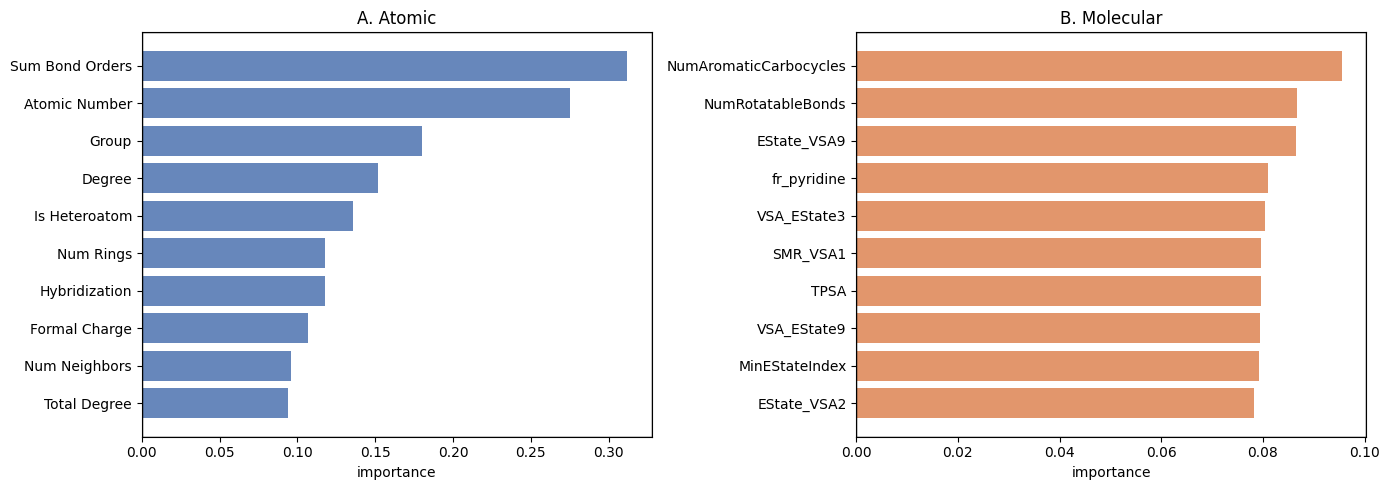

saved 2-method feature importance comparison (A-B) to figures/feature_ablation_atomic_vs_molecular.pdf
Feature Ablation — top atom features:
           feature  importance
0  Sum Bond Orders    0.312095
1    Atomic Number    0.274851
2            Group    0.180006
3           Degree    0.151953
4    Is Heteroatom    0.135465
5        Num Rings    0.117977
6    Hybridization    0.117884
7    Formal Charge    0.106475
8    Num Neighbors    0.096119
9     Total Degree    0.093796

Feature Ablation — top descriptors:


,descriptor,importance
0,NumAromaticCarbocycles,0.095538
1,NumRotatableBonds,0.086618
2,EState_VSA9,0.086449
3,fr_pyridine,0.081014
4,VSA_EState3,0.080421
5,SMR_VSA1,0.079649
6,TPSA,0.079593
7,VSA_EState9,0.079479
8,MinEStateIndex,0.079268
9,EState_VSA2,0.078228


In [22]:
fa_df = feature_ablation_on_batch(explain_model, sample_batch)
fa_df.to_csv(f'{config.OUTPUT_DIR}/feature_ablation_importance.csv', index=False)

desc_fa_df = feature_ablation_descriptors(explain_model, sample_batch, explain_descriptor_cols)
desc_fa_df.to_csv(f'{config.OUTPUT_DIR}/descriptor_feature_ablation_importance.csv', index=False)

compare.save_feature_importance_pdf(
    {'Atomic': fa_df.rename(columns={'feature': 'name'}),
     'Molecular': desc_fa_df.rename(columns={'descriptor': 'name'})},
    output_path=f'{config.FIGURE_DIR}/feature_ablation_atomic_vs_molecular.pdf',
    feature_col='name',
)

print("Feature Ablation — top atom features:")
print(fa_df.head(10))
print("\nFeature Ablation — top descriptors:")
desc_fa_df.head(10)

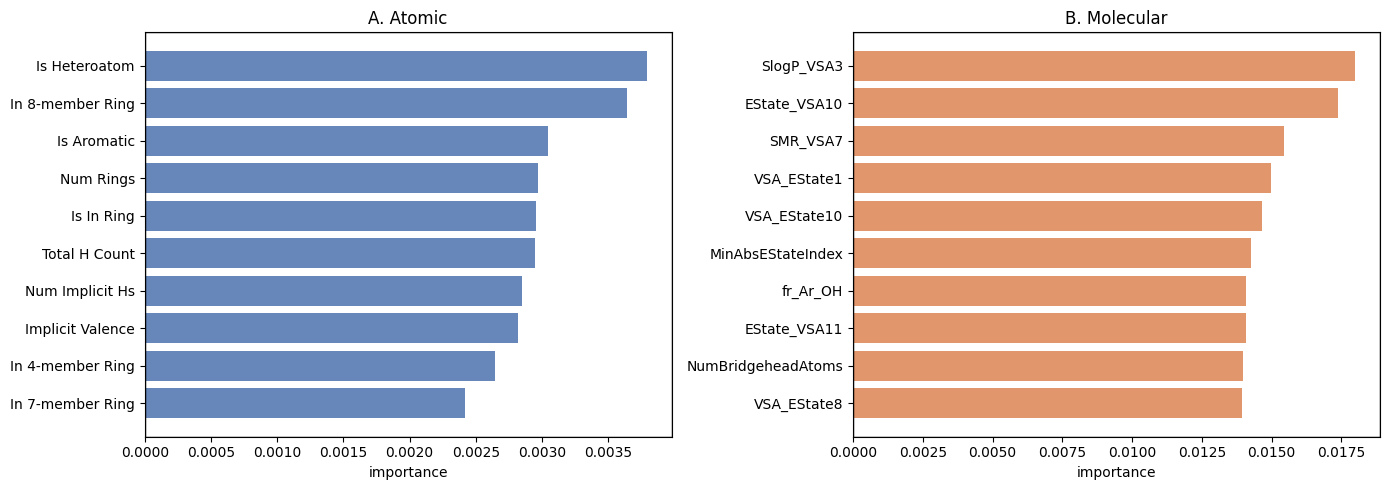

saved 2-method feature importance comparison (A-B) to figures/saliency_atomic_vs_molecular.pdf
Saliency — top atom features:
            feature  importance
0     Is Heteroatom    0.003790
1  In 8-member Ring    0.003639
2       Is Aromatic    0.003044
3         Num Rings    0.002971
4        Is In Ring    0.002952
5     Total H Count    0.002949
6   Num Implicit Hs    0.002847
7  Implicit Valence    0.002817
8  In 4-member Ring    0.002642
9  In 7-member Ring    0.002419

Saliency — top descriptors:


,descriptor,importance
0,SlogP_VSA3,0.017990
1,EState_VSA10,0.017398
2,SMR_VSA7,0.015437
3,VSA_EState1,0.014967
4,VSA_EState10,0.014676
5,MinAbsEStateIndex,0.014274
6,fr_Ar_OH,0.014085
7,EState_VSA11,0.014077
8,NumBridgeheadAtoms,0.013993
9,VSA_EState8,0.013950


In [23]:
sal_df = saliency_on_batch(explain_model, sample_batch)
sal_df.to_csv(f'{config.OUTPUT_DIR}/saliency_importance.csv', index=False)

desc_sal_df = saliency_descriptors(explain_model, sample_batch, explain_descriptor_cols)
desc_sal_df.to_csv(f'{config.OUTPUT_DIR}/descriptor_saliency_importance.csv', index=False)

compare.save_feature_importance_pdf(
    {'Atomic': sal_df.rename(columns={'feature': 'name'}),
     'Molecular': desc_sal_df.rename(columns={'descriptor': 'name'})},
    output_path=f'{config.FIGURE_DIR}/saliency_atomic_vs_molecular.pdf',
    feature_col='name',
)

print("Saliency — top atom features:")
print(sal_df.head(10))
print("\nSaliency — top descriptors:")
desc_sal_df.head(10)

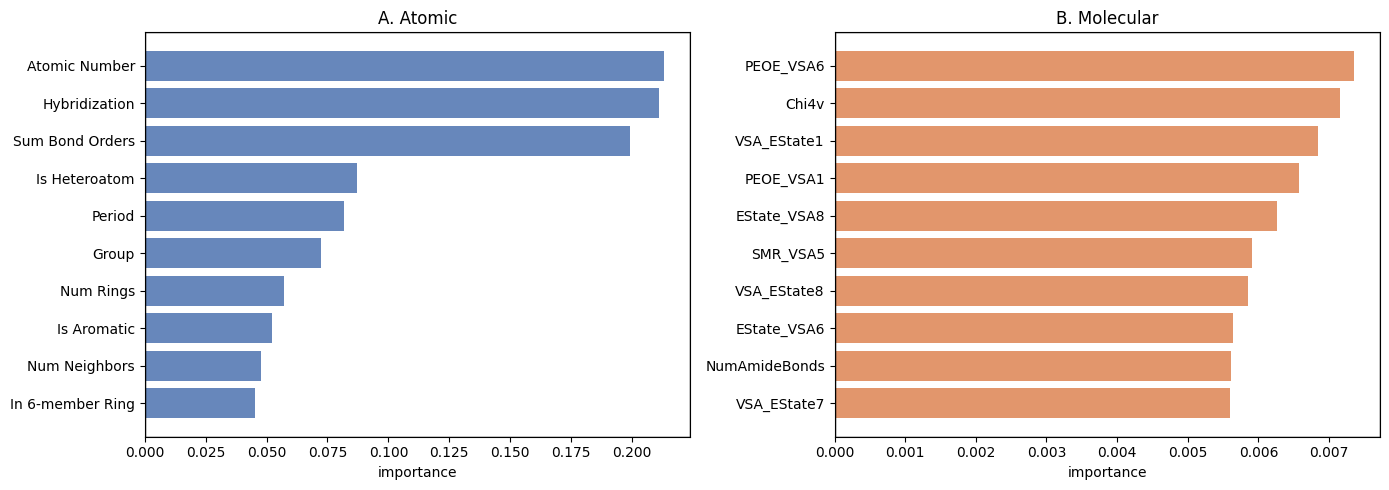

saved 2-method feature importance comparison (A-B) to figures/shap_atomic_vs_molecular.pdf
SHAP — top atom features:
            feature  importance
0     Atomic Number    0.213177
1     Hybridization    0.211003
2   Sum Bond Orders    0.199320
3     Is Heteroatom    0.087243
4            Period    0.081692
5             Group    0.072444
6         Num Rings    0.057046
7       Is Aromatic    0.052117
8     Num Neighbors    0.047857
9  In 6-member Ring    0.045405

SHAP — top descriptors:


,descriptor,importance
0,PEOE_VSA6,0.007354
1,Chi4v,0.007149
2,VSA_EState1,0.006851
3,PEOE_VSA1,0.006571
4,EState_VSA8,0.006262
5,SMR_VSA5,0.005904
6,VSA_EState8,0.005847
7,EState_VSA6,0.005647
8,NumAmideBonds,0.005619
9,VSA_EState7,0.005605


In [24]:
shap_df = shap_on_batch(explain_model, sample_batch)
shap_df.to_csv(f'{config.OUTPUT_DIR}/shap_importance.csv', index=False)

desc_shap_df = shap_descriptors(explain_model, sample_batch, explain_descriptor_cols)
desc_shap_df.to_csv(f'{config.OUTPUT_DIR}/descriptor_shap_importance.csv', index=False)

compare.save_feature_importance_pdf(
    {'Atomic': shap_df.rename(columns={'feature': 'name'}),
     'Molecular': desc_shap_df.rename(columns={'descriptor': 'name'})},
    output_path=f'{config.FIGURE_DIR}/shap_atomic_vs_molecular.pdf',
    feature_col='name',
)

print("SHAP — top atom features:")
print(shap_df.head(10))
print("\nSHAP — top descriptors:")
desc_shap_df.head(10)

## Summary of outputs

Running the full pipeline produces the following artifacts, organized by category.

**Trained models**
`trained_models/{gnn_model, gat_model, gcn_transformer_model, gat_transformer_model}_best.pth` — final weights for each of the four GNN architectures (GCN, GAT, GCN-Transformer, GAT-Transformer), along with the corresponding `_best_params.json` files recording the hyperparameters each checkpoint was trained with.

**Training records**
`training_history/*_history.pkl` — per-epoch training and validation metrics (loss, accuracy, AUC) for each architecture, the basis for the training curve figures.

**Performance summaries**
- `test_results/cross_validation_summary.json` — mean and standard deviation for each metric across cross-validation folds; this is the figure to cite for the cross-validated results.
- `test_results/{name}_results.pkl` — held-out test set predictions and metrics for every model, baseline and GNN alike, from the 80/20 split. This is the source for the confusion matrices, ROC curves, and final reported test performance.
- `test_results/{name}_tuning_results.csv` — the hyperparameter combinations evaluated for each GNN, with mean validation AUC across the tuning folds.

**Explainability outputs**
Five methods — GNNExplainer, Integrated Gradients, Feature Ablation, Saliency, and SHAP — each applied to both branches of the model: the atom-level graph structure and the molecular descriptor branch. This yields ten importance files in total:
- Atom-level: `gnnexplainer_importance.csv`, `integrated_gradients_importance.csv`, `feature_ablation_importance.csv`, `saliency_importance.csv`, `shap_importance.csv`
- Descriptor-level: `descriptor_gnnexplainer_importance.csv`, `descriptor_integrated_gradients_importance.csv`, `descriptor_feature_ablation_importance.csv`, `descriptor_saliency_importance.csv`, `descriptor_shap_importance.csv`

**Figures**
All comparison and explainability figures are saved to `figures/` as publication-ready PDFs: confusion matrices (primary and balanced-subsample supplementary versions), training curves, hyperparameter tuning results, the multi-metric model comparison, and one atomic-vs-molecular comparison per explainability method.

